# Benchmark diário: Chronos-2, MLP e LSTM no Brasil

Previsão da **energia do dia seguinte**, expressa também como potência média diária: `Active_Power = energia_kwh / 24`. O total é a soma dos oito inversores da usina `07-07FX`, depois da conferência entre o contador diário e a diferença do contador acumulado.

A reconstrução segue o código enviado: **284 dias válidos e 81 lacunas em 2025**, sem imputar dias. Com três dias anteriores consecutivos, são **160 janelas de treino, 26 de validação e 44 de teste**. Os cenários com e sem covariáveis usam as mesmas datas.

Este notebook foi atualizado no próprio arquivo. Configuração e resultados desta base ficam em `experimentos/chronos_diario_contadores/`. Os resultados da base anterior continuam em `experimentos/chronos_diario/`.

O CSV disponível no projeto é `data/raw/brasil/Leopoldo-fixa-inv.csv`. O arquivo com sufixo `(1)` mencionado no código enviado não foi localizado. O manifesto registra o arquivo efetivamente usado e seu hash.

As seções 7 e 8 acrescentam **MLP e LSTM treinadas do zero somente no Brasil**, com as mesmas janelas e alvos, e a comparação final com Chronos e persistência.


In [10]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
from IPython.display import display, Image, Markdown

RAIZ = Path.cwd()
if not (RAIZ / 'data/raw/brasil/Leopoldo-fixa-inv.csv').exists():
    raise FileNotFoundError('Execute a partir da raiz do projeto.')
sys.path.insert(0, str(RAIZ / 'src'))
# Atualiza as funções mesmo se este kernel já executou a versão anterior.
import importlib
from energia_transfer import chronos_experimentos, chronos_diario, chronos_diario_contadores
for modulo in [chronos_experimentos, chronos_diario, chronos_diario_contadores]:
    importlib.reload(modulo)
from energia_transfer.chronos_diario_contadores import preparar, treinar, avaliar, graficos

dados_diarios = preparar(RAIZ)
PASTA = dados_diarios['pasta']
RESULTADOS = dados_diarios['out']
config = dados_diarios['cfg']


  dominio  particao    n  dias_validos  janelas_so_contadores     inicio        fim
   brasil    treino  160         202.0                  160.0 2025-02-02 2025-09-30
   brasil validacao   26          29.0                   26.0 2025-10-01 2025-10-31
   brasil     teste   44          53.0                   44.0 2025-11-01 2025-12-31
australia    treino 3392           NaN                    NaN 2013-07-28 2022-12-31
australia validacao  352           NaN                    NaN 2023-01-01 2023-12-31
Contadores: 284 dias válidos; 81 lacunas.


## 1. Reconstrução e faltantes

1. Filtrar `07-07FX`; converter UTC para `America/Sao_Paulo`, arredondar para cinco minutos e consolidar duplicatas pela mediana. Valores negativos viram ausentes.
2. Para cada inversor e dia: `e1` é o máximo de `daily_power_yields_kwh` após as 6h. `e2` é a diferença entre as medianas do contador total após as 19h e antes das 4h.
3. Aprovar o inversor quando `0 ≤ e1 ≤ 1600 kWh`, `e2 ≥ 0` e `abs(e1 - e2) ≤ max(8 kWh, 0.03 * e1)`.
4. Aprovar o dia somente com **oito equipamentos distintos consistentes**, somar suas energias e dividir por 24 h. Preservar os 365 dias no calendário.

A concordância dos contadores permite aproveitar energia de dias com falhas na telemetria de potência. Não preenchemos os intervalos perdidos nem dias reprovados. A conferência não substitui a calibração dos medidores.

Em relação à seleção anterior, entram 33 dias e saem 46. O total aprovado diminui, mas as janelas válidas de teste passam de 23 para 44. As regras e o alvo mudaram, portanto a comparação de erro entre bases exige cuidado.


Dias no calendário: 365
Dias aprovados: 284
Dias reprovados: 81
Dias recuperados: 33
Dias aprovados anteriormente que não passam nos contadores: 46


,dominio,particao,n,dias_validos,janelas_so_contadores,inicio,fim
0,brasil,treino,160,202.0,160.0,2025-02-02,2025-09-30
1,brasil,validacao,26,29.0,26.0,2025-10-01,2025-10-31
2,brasil,teste,44,53.0,44.0,2025-11-01,2025-12-31
3,australia,treino,3392,NaN,NaN,2013-07-28,2022-12-31
4,australia,validacao,352,NaN,NaN,2023-01-01,2023-12-31


,historico_dias,particao,janelas_so_contadores,janelas_modelo
0,1,treino,184,184
1,1,validacao,28,28
2,1,teste,50,50
3,3,treino,160,160
4,3,validacao,26,26
5,3,teste,44,44
6,7,treino,128,128
7,7,validacao,22,22
8,7,teste,33,33
9,14,treino,88,88


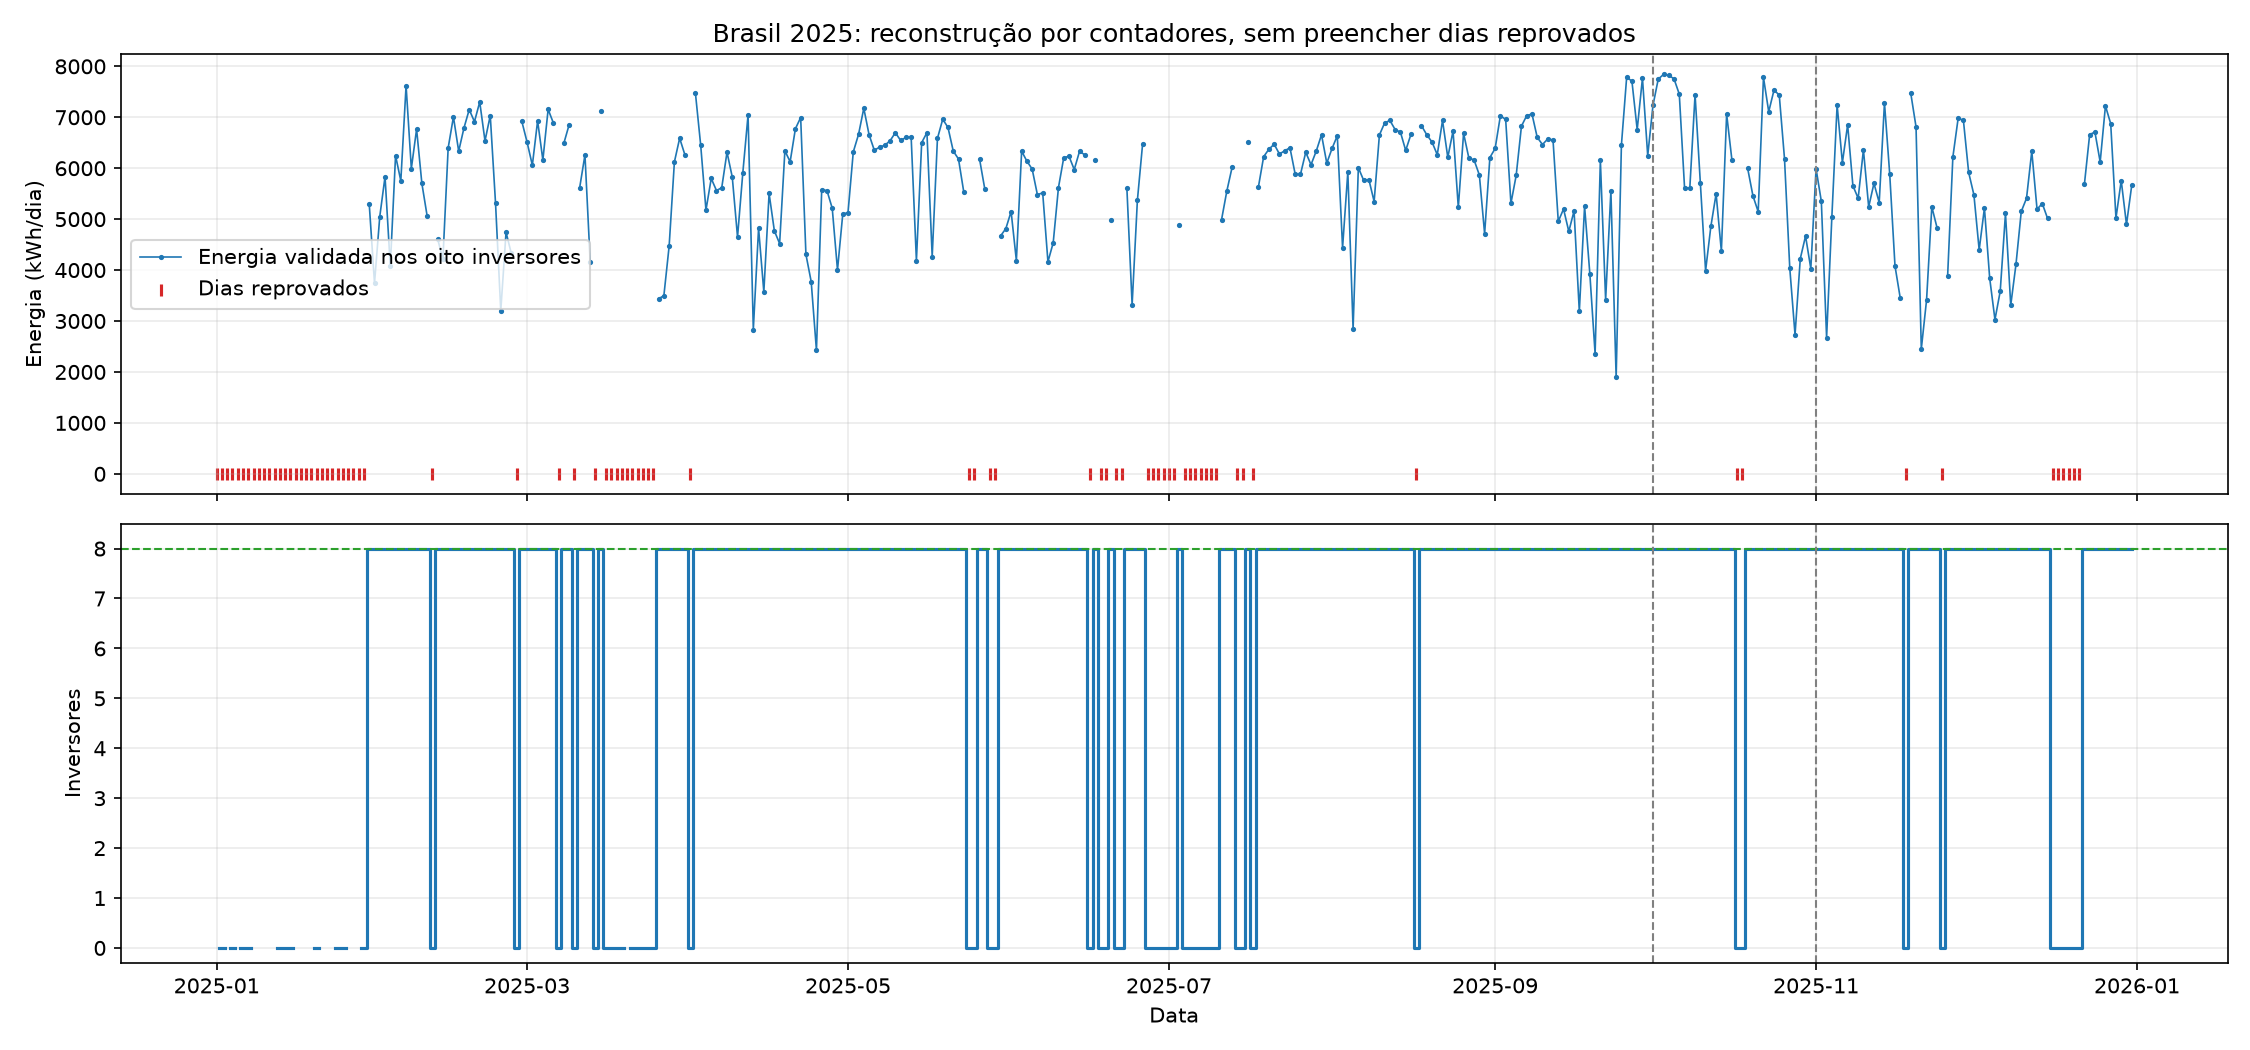

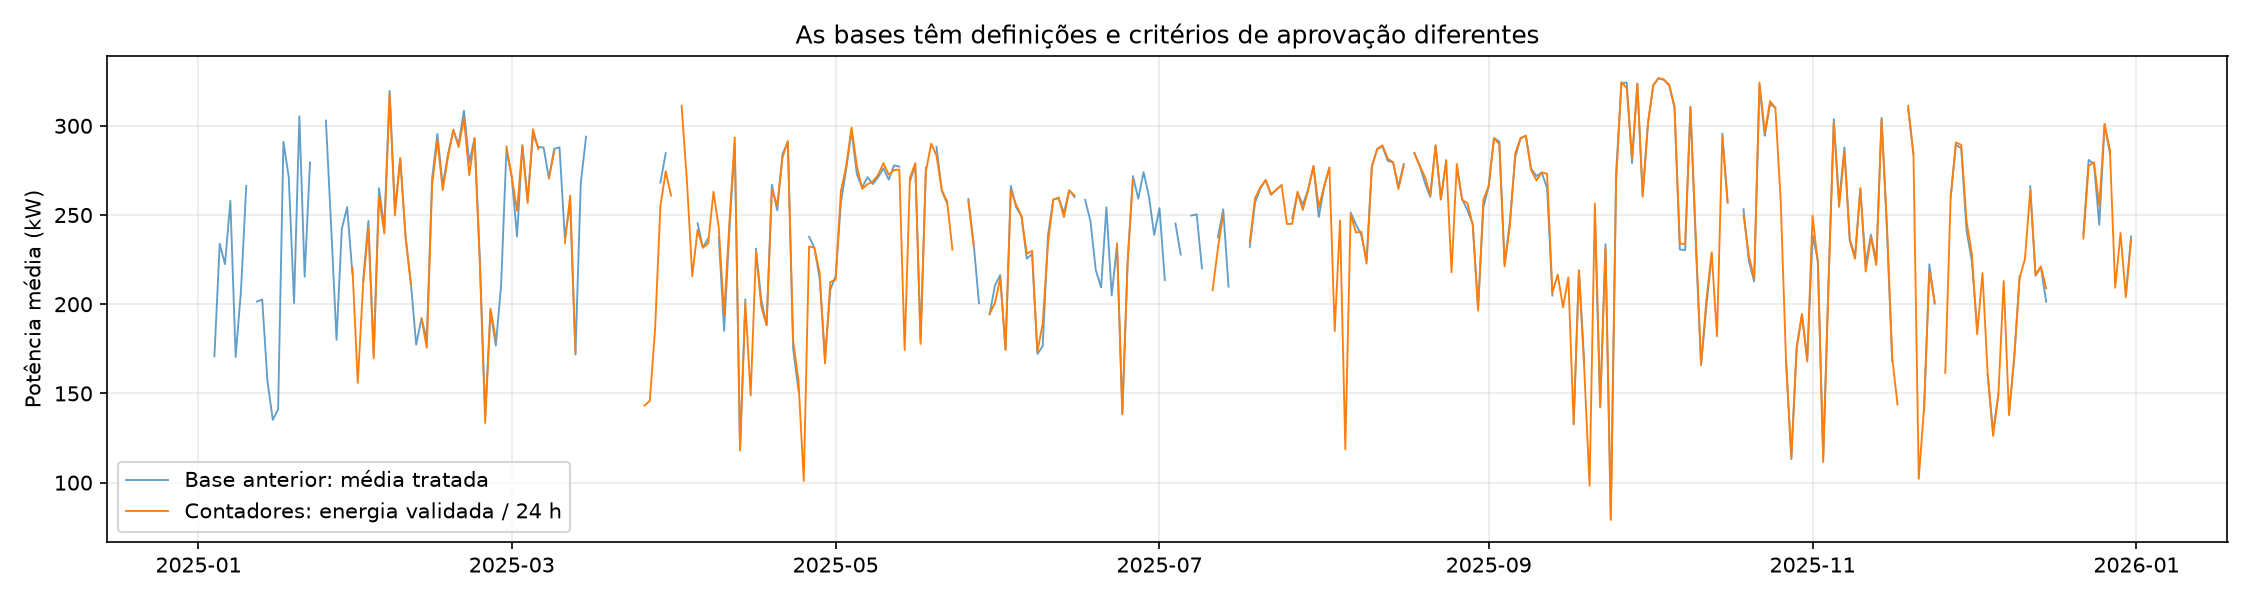

In [11]:
auditoria = pd.read_csv(RESULTADOS / 'auditoria_calendario_brasil.csv', parse_dates=['timestamp'])
resumo_reconstrucao = dados_diarios['resumo_reconstrucao']
print('Dias no calendário:', len(auditoria))
print('Dias aprovados:', int(auditoria.valido.sum()))
print('Dias reprovados:', int((~auditoria.valido).sum()))
print('Dias recuperados:', resumo_reconstrucao['dias_recuperados'])
print('Dias aprovados anteriormente que não passam nos contadores:', resumo_reconstrucao['dias_so_base_anterior'])
display(pd.read_csv(RESULTADOS / 'particoes.csv'))
display(pd.read_csv(RESULTADOS / 'janelas_por_historico.csv'))
graficos(dados_diarios)
for figura in ['reconstrucao_contadores.png', 'comparacao_bases.png']:
    display(Image(filename=str(RESULTADOS / figura)))


## 2. Entradas, horizonte e disponibilidade

**Horizonte: um dia; histórico: três dias completos anteriores e consecutivos.** No cenário univariado, a entrada é a potência média diária normalizada pela capacidade AC (Brasil: 1000 kW; Austrália: 24 kW). Nos demais, acrescentamos temperatura, umidade, GHI e calendário anuais dos mesmos dias passados. Vento fica fora.

No dia previsto, somente seno e cosseno do dia do ano são conhecidos. Meteorologia futura não entra no modelo; não usamos observações do alvo como covariáveis. A seleção de janelas não exige meteorologia no próprio dia alvo.

O clima brasileiro vem do arquivo público diário ERA5 já disponível no projeto, inclusive para dias que não passavam na base antiga. A reanálise é histórica: sua latência operacional não foi simulada.

A Austrália mantém a base diária anterior. O calendário com lacunas é preservado: nenhuma janela atravessa um dia sem energia validada.


In [12]:
contrato_entradas = pd.DataFrame([
    {'variavel': 'Active_Power = energia_kwh / 24 / capacidade_AC', 'passado': '3 dias', 'dia_previsto': 'alvo desconhecido'},
    *[{'variavel': c, 'passado': '3 dias', 'dia_previsto': 'desconhecido'} for c in config['colunas_covariaveis'] if c not in config['colunas_futuras']],
    *[{'variavel': c, 'passado': '3 dias', 'dia_previsto': 'conhecido pela data'} for c in config['colunas_futuras']],
])
display(contrato_entradas)
for particao in ['treino', 'validacao', 'teste']:
    j = dados_diarios['janelas']['brasil', particao]
    assert np.isfinite(j['X']).all() and np.isfinite(j['y']).all()
    assert np.isnan(j['calendario_futuro'][:, :3]).all()
    print(particao, 'X:', j['X'].shape, 'alvos:', len(j['y']), 'datas:', j['datas'].min().date(), 'até', j['datas'].max().date())
j = dados_diarios['janelas']['brasil', 'treino']
display(pd.DataFrame(j['X'][0], columns=['Active_Power_pu'] + config['colunas_covariaveis']))


,variavel,passado,dia_previsto
0,Active_Power = energia_kwh / 24 / capacidade_AC,3 dias,alvo desconhecido
1,Weather_Temperature_Celsius,3 dias,desconhecido
2,Weather_Relative_Humidity,3 dias,desconhecido
3,Global_Horizontal_Radiation,3 dias,desconhecido
4,dia_ano_sin,3 dias,conhecido pela data
5,dia_ano_cos,3 dias,conhecido pela data


treino X: (160, 3, 6) alvos: 160 datas: 2025-02-02 até 2025-09-30
validacao X: (26, 3, 6) alvos: 26 datas: 2025-10-01 até 2025-10-31
teste X: (44, 3, 6) alvos: 44 datas: 2025-11-01 até 2025-12-31


,Active_Power_pu,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,dia_ano_sin,dia_ano_cos
0,0.220458,22.358334,81.916664,191.708328,0.478734,0.877960
1,0.155929,21.883333,84.500000,163.791672,0.493776,0.869589
2,0.210500,21.970833,86.208336,153.125000,0.508671,0.860961


## 3. Repetição dos cinco cenários LoRA

| Cenário | Dados do ajuste | Covariáveis |
|---|---|---|
| Individual | Brasil | Nenhuma |
| Portfólio | Austrália e Brasil, 160 origens por usina | Nenhuma |
| Individual com covariáveis | Brasil | Meteorologia passada e calendário |
| Portfólio com covariáveis | Austrália e Brasil, 160 origens por usina | Meteorologia passada e calendário |
| Transferência sem Brasil | Somente Austrália | Meteorologia passada e calendário |

Mantemos a configuração anterior: até 200 passos, rank 8, alpha 16, taxa de aprendizado 2e-5, oito origens por lote e semente 42. A verificação ocorre a cada 25 passos, com paciência de quatro verificações. O hash dos pesos congelados é conferido antes e depois do ajuste.

A escolha de checkpoint individual usa as 26 origens brasileiras de outubro. O portfólio usa 19 de cada usina, respeitando o orçamento de 38 origens. A transferência sem Brasil usa somente validação australiana. Os adaptadores desta base têm outra assinatura e pasta; os antigos não são reutilizados como se tivessem sido treinados neste alvo.

Referência do experimento: [artigo solicitado](https://towardsdatascience.com/five-ways-to-fine-tune-chronos-2-the-time-series-foundation-model/) e [notebook do autor](https://github.com/ShuaiGuo16/chronos-2-forecasting/blob/main/02_chronos2_fine_tuning_building_demand.ipynb).


In [13]:
display(pd.DataFrame(config['cenarios']))
print('Passos máximos:', config['num_steps'], '| Semente:', config['semente'])
# Se a CLI estiver treinando, aguarda o bloqueio e reutiliza os adaptadores verificados.
treinar(dados_diarios)
auditorias_lora = [json.loads(p.read_text(encoding='utf-8')) for p in (PASTA / 'modelos').glob('*/concluido.json')]
for a in auditorias_lora:
    assert a['congelados_sha256_antes'] == a['congelados_sha256_depois']
    assert a['assinatura'] == dados_diarios['assinatura']
display(pd.DataFrame(auditorias_lora)[['cenario', 'passos_executados', 'parametros_treinaveis', 'melhor_loss', 'segundos']])


,nome,dominios,calendario
0,individual,[brasil],False
1,portfolio,"[australia, brasil]",False
2,individual_covariaveis,[brasil],True
3,portfolio_covariaveis,"[australia, brasil]",True
4,transferencia_sem_brasil,[australia],True


Passos máximos: 200 | Semente: 42


Loading weights: 100%|██████████| 170/170 [00:01<00:00, 157.96it/s]

Reutilizando adaptador verificado: individual


Reutilizando adaptador verificado: portfolio
Reutilizando adaptador verificado: individual_covariaveis
Reutilizando adaptador verificado: portfolio_covariaveis
Reutilizando adaptador verificado: transferencia_sem_brasil


,cenario,passos_executados,parametros_treinaveis,melhor_loss,segundos
0,individual,200,1206912,0.967918,85.056891
1,individual_covariaveis,200,1206912,0.161162,126.220569
2,portfolio,200,1206912,1.012646,87.334265
3,portfolio_covariaveis,200,1206912,0.168189,124.685691
4,transferencia_sem_brasil,200,1206912,0.169125,145.616616


## 4. Validação e teste

Treino brasileiro até setembro; validação em outubro; teste em novembro e dezembro. A Austrália mantém treino até 2022 e validação em 2023. Cada tarefa contém três dias passados e um alvo consecutivo. Com `min_past=3`, não criamos pares entre blocos separados.

Escolhemos pelo RMSE das 26 datas de validação brasileira, antes de calcular as métricas das 44 datas de teste. Persistência participa da seleção; a transferência sem Brasil é reportada separadamente e fica fora dessa seleção.

**Todos os métodos são avaliados nas mesmas 44 datas e no mesmo alvo reconstruído.** A avaliação é de um passo, com os três dias observados anteriores atualizados a cada origem de previsão. MAE/RMSE em kW se referem à potência média de 24 h. Multiplicar por 24 fornece MAE/RMSE em kWh/dia. WAPE permanece igual.

As métricas antigas de MLP/LSTM não entram neste ranking. As seções 7 e 8 treinam novas redes locais nesta referência e apresentam o benchmark conjunto. O teste já foi examinado em estudos anteriores, portanto os resultados continuam exploratórios.


In [ ]:
df_comparacao_diaria = avaliar(dados_diarios)
graficos(dados_diarios)
decisao = json.loads((RESULTADOS / 'decisao_validacao.json').read_text(encoding='utf-8'))
print('Escolha pelo RMSE na validação:', decisao['escolhido']['modelo'])
display(pd.read_csv(RESULTADOS / 'metricas_validacao.csv').round(3))
display(df_comparacao_diaria.round(3))
for figura in ['comparacao_diaria.png', 'previsoes_diarias.png']:
    display(Image(filename=str(RESULTADOS / figura)))


validacao: zero_shot_univariado; RMSE 56.477 kW
validacao: zero_shot_covariaveis; RMSE 59.523 kW
validacao: individual; RMSE 53.703 kW
validacao: portfolio; RMSE 53.022 kW
validacao: individual_covariaveis; RMSE 53.362 kW
validacao: portfolio_covariaveis; RMSE 52.935 kW
validacao: transferencia_sem_brasil; RMSE 53.668 kW
teste: zero_shot_univariado; RMSE 56.510 kW
teste: zero_shot_covariaveis; RMSE 59.684 kW
teste: individual; RMSE 46.899 kW
teste: portfolio; RMSE 47.601 kW
teste: individual_covariaveis; RMSE 46.909 kW
teste: portfolio_covariaveis; RMSE 46.811 kW
teste: transferencia_sem_brasil; RMSE 48.721 kW


## 5. Qualidade dos contadores e alvos usados

A qualidade agora é conferida pelos totais de energia, sem exigir 95% de telemetria de potência. O arquivo por inversor registra bordas ausentes, contadores divergentes, valores fora do limite e diferença acumulada negativa. Os motivos podem ocorrer simultaneamente.

O calendário de qualidade contém os oito inversores em todos os 365 dias. `energia_bruta_kwh` é apenas diagnóstico e pode conter uma soma parcial: o alvo válido é **`energia_kwh`**, que permanece NaN quando qualquer inversor reprova. Não substituir ausentes por zero.


In [ ]:
qualidade_inv = pd.read_csv(RESULTADOS / 'qualidade_calendario_por_inversor.csv', parse_dates=['dia'])
falhas = ['sem_registro_apos_6h', 'sem_inicio', 'sem_fim', 'sem_contador_diario', 'energia_fora_limite', 'acumulado_negativo', 'contadores_divergentes']
display(pd.DataFrame({'motivo': falhas, 'inversor_dias': [int(qualidade_inv[c].eq(True).sum()) for c in falhas]}))
previsoes_diarias = pd.read_csv(RESULTADOS / 'previsoes_teste.csv', parse_dates=['timestamp'])
assert previsoes_diarias.n_inversores_consistentes.eq(8).all()
np.testing.assert_allclose(previsoes_diarias.referencia_diaria_kw*24, previsoes_diarias.energia_real_kwh)
print('Alvos de teste com os oito inversores aprovados:', len(previsoes_diarias))
display(previsoes_diarias[['timestamp', 'energia_real_kwh', 'referencia_diaria_kw', 'n_inversores_consistentes', 'maior_diferenca_contadores_kwh']])


,motivo,inversor_dias
0,sem_registro_apos_6h,197
1,sem_inicio,339
2,sem_fim,216
3,sem_contador_diario,0
4,energia_fora_limite,0
5,acumulado_negativo,0
6,contadores_divergentes,0


Alvos de teste com os oito inversores aprovados: 44


,timestamp,energia_real_kwh,referencia_diaria_kw,n_inversores_consistentes,maior_diferenca_contadores_kwh
0,2025-11-01,5988.4,249.516667,8.0,0.8
1,2025-11-02,5349.8,222.908333,8.0,0.9
2,2025-11-03,2676.5,111.520833,8.0,0.9
3,2025-11-04,5045.4,210.225000,8.0,0.6
4,2025-11-05,7240.5,301.687500,8.0,0.6
5,2025-11-06,6108.9,254.537500,8.0,0.7
6,2025-11-07,6851.7,285.487500,8.0,0.5
7,2025-11-08,5655.5,235.645833,8.0,0.7
8,2025-11-09,5410.6,225.441667,8.0,0.7
9,2025-11-10,6362.1,265.087500,8.0,0.7


## 6. Curvas e arquivos

As perdas de treinamento e validação são as perdas internas de quantis. Cenários com números diferentes de covariáveis não devem ser comparados apenas por essas curvas; usamos os erros na mesma referência brasileira.

- Base completa: `data/processed/brasil/leopoldo_diario_contadores_auditado.csv`.
- Configuração, dados de entrada, adaptadores e resultados: `experimentos/chronos_diario_contadores/`.
- Resultados da definição anterior de potência média: `experimentos/chronos_diario/`.

Uma única semente e 26 alvos de validação não estabelecem superioridade estatística. Concordância entre contadores também não exclui erro comum de medição. Não mudamos as regras nem os hiperparâmetros em função do teste.


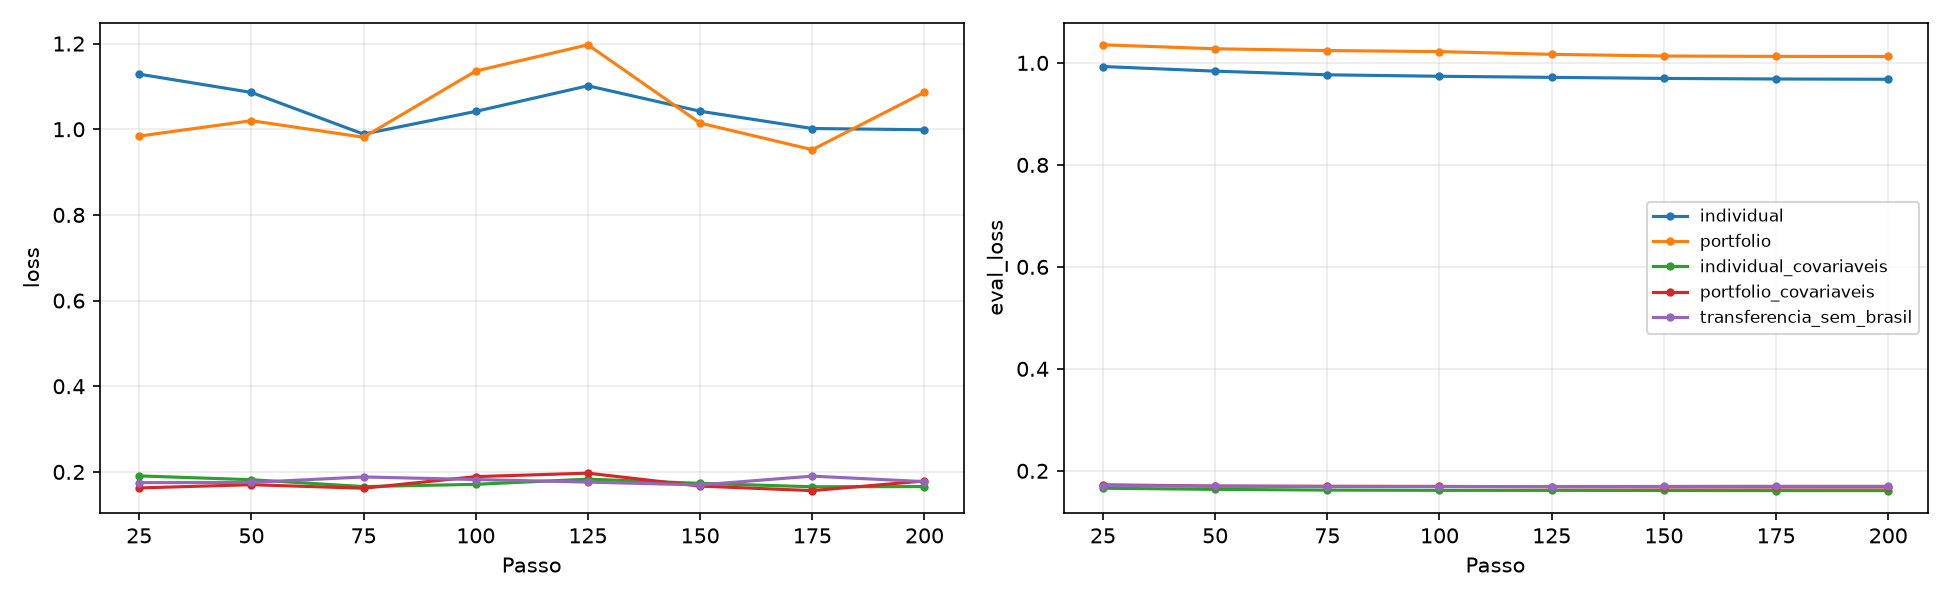

# Chronos-2 diário com contadores — Brasil

Alvo: soma da energia diária validada dos oito inversores (kWh), dividida por 24 h para obter potência média em kW.
284 dias aprovados; 81 dias reprovados permanecem ausentes. Sem imputação diária.
Histórico de três dias consecutivos; previsão de um dia. Partições cronológicas: treino até setembro, validação em outubro, teste em novembro–dezembro.
Covariáveis: temperatura, umidade, GHI e calendário dos dias passados; futuro: somente calendário. Sem vento. ERA5 é reanálise histórica, com disponibilidade operacional não modelada.
Austrália preservada do estudo diário anterior, normalizada por 24 kW AC; Brasil por 1000 kW AC. A origem não foi reconstruída por contadores.
Os contadores validam totais diários apesar das lacunas de telemetria. Concordância entre contadores não prova calibração dos medidores nem exclui erro comum.
Mantidos os cinco cenários e o orçamento do piloto anterior: até 200 passos LoRA, rank 8, semente 42. Transferência sem Brasil usa somente dados australianos para ajuste/checkpoint.
O teste já foi consultado em estudos anteriores. Comparação exploratória, com apenas uma semente e poucos dias de validação.
As métricas MLP/LSTM e Chronos do alvo anterior não entram neste ranking: referência e datas mudaram.

| Partição | Dias válidos | Janelas de 3 dias |
|---|---:|---:|
| treino | 202 | 160 |
| validacao | 29 | 26 |
| teste | 53 | 44 |

Escolha pela validação: **portfolio_covariaveis**.

| Modelo | N teste | MAE kW | RMSE kW | MAE kWh/dia | RMSE kWh/dia | WAPE % |
|---|---:|---:|---:|---:|---:|---:|
| persistencia | 44 | 42.961 | 50.301 | 1031.061 | 1207.213 | 19.550 |
| zero_shot_univariado | 44 | 46.585 | 56.510 | 1118.029 | 1356.249 | 21.199 |
| zero_shot_covariaveis | 44 | 50.104 | 59.684 | 1202.484 | 1432.423 | 22.800 |
| individual | 44 | 38.775 | 46.899 | 930.593 | 1125.565 | 17.645 |
| portfolio | 44 | 39.191 | 47.601 | 940.577 | 1142.419 | 17.834 |
| individual_covariaveis | 44 | 38.479 | 46.909 | 923.491 | 1125.815 | 17.510 |
| portfolio_covariaveis | 44 | 38.610 | 46.811 | 926.633 | 1123.454 | 17.570 |
| transferencia_sem_brasil | 44 | 40.537 | 48.721 | 972.880 | 1169.294 | 18.447 |

Fonte e implementação de referência: https://github.com/ShuaiGuo16/chronos-2-forecasting/blob/main/02_chronos2_fine_tuning_building_demand.ipynb

CSV bruto efetivamente usado: `data/raw/brasil/Leopoldo-fixa-inv.csv`. Seu hash consta no manifesto.


Base reconstruída: c:\Users\Camille\Documents\UFJF\TCC\Leopoldo\data\processed\brasil\leopoldo_diario_contadores_auditado.csv
Resultados: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\experimentos\chronos_diario_contadores\resultados


In [ ]:
display(Image(filename=str(RESULTADOS / 'curvas_lora_diario.png')))
display(Markdown((RESULTADOS / 'relatorio.md').read_text(encoding='utf-8')))
print('Base reconstruída:', RAIZ / 'data/processed/brasil/leopoldo_diario_contadores_auditado.csv')
print('Resultados:', RESULTADOS)


## 7. MLP e LSTM treinadas somente com dados brasileiros

Estas são redes **treinadas do zero**, sem pesos australianos, sem pré-treinamento e com saída direta. Não somamos uma correção à persistência.

As duas recebem os mesmos **três dias consecutivos e seis variáveis históricas** dos cenários Chronos com covariáveis: potência média, temperatura, umidade, GHI e seno/cosseno anual. Também recebem o calendário conhecido do dia previsto (seno/cosseno), concatenado à entrada achatada da MLP ou à saída recorrente da LSTM. Meteorologia futura e vento ficam fora.

| Configuração | MLP | LSTM |
|---|---|---|
| Camadas | 32 e 16 neurônios, ReLU | Uma camada, 16 unidades |
| Saída | Um valor direto | Um valor direto |
| Dados de treino | 160 janelas brasileiras | 160 janelas brasileiras |
| Validação | 26 datas de outubro | 26 datas de outubro |
| Otimizador | AdamW, taxa 0.001, weight decay 0.0001 | Idem |
| Treinamento | Lote 16, até 200 épocas, paciência 30 | Idem |

A normalização de entradas e alvo é ajustada **somente no treino brasileiro**. O calendário futuro mantém sua escala fixa [-1,1]. A parada antecipada escolhe o menor MSE da validação. A LSTM inicia seus estados em zero para cada janela, sem transportar estado entre blocos ou lotes.

A **semente 42 é fixada previamente para a tabela principal**, como nos adaptadores Chronos. Também executamos as sementes 7, 21, 84 e 123, apresentadas separadamente para mostrar a variação de inicialização. Não selecionamos uma semente pelo teste. O desvio entre sementes não é intervalo de confiança nem teste de significância.

Os orçamentos diferem: as redes locais usam épocas e MSE; Chronos usa passos LoRA e perda de quantis. A comparação final usa os mesmos alvos em kW e kWh/dia.


,seed_principal,seeds,epocas_maximas,paciencia,learning_rate,batch_size
0,42,"[42, 7, 21, 84, 123]",200,30,0.001,16


Reutilizando mlp Brasil seed=42.
Reutilizando mlp Brasil seed=7.
Reutilizando mlp Brasil seed=21.
Reutilizando mlp Brasil seed=84.
Reutilizando mlp Brasil seed=123.
Reutilizando lstm Brasil seed=42.
Reutilizando lstm Brasil seed=7.
Reutilizando lstm Brasil seed=21.
Reutilizando lstm Brasil seed=84.
Reutilizando lstm Brasil seed=123.


,arquitetura,seed,melhor_epoca,epocas_executadas,parametros,segundos
0,mlp,42,16,46,1217,2.205
1,mlp,7,14,44,1217,1.908
2,mlp,21,18,48,1217,1.673
3,mlp,84,17,47,1217,1.612
4,mlp,123,18,48,1217,1.757
5,lstm,42,34,64,1555,3.065
6,lstm,7,39,69,1555,3.266
7,lstm,21,29,59,1555,2.836
8,lstm,84,24,54,1555,2.572
9,lstm,123,30,60,1555,2.769


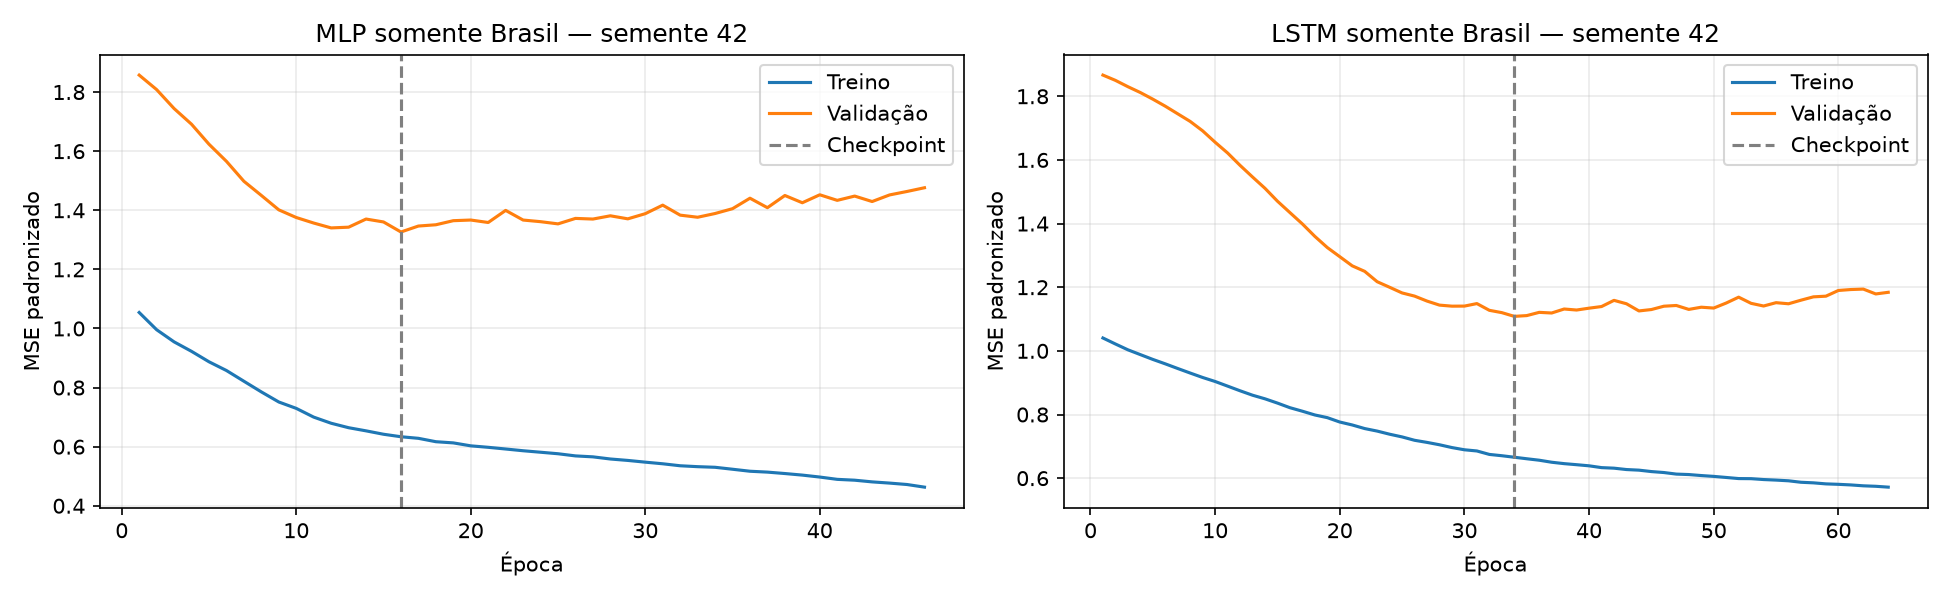

In [ ]:
import importlib
from energia_transfer import benchmark_diario_brasil
importlib.reload(benchmark_diario_brasil)
from energia_transfer.benchmark_diario_brasil import executar_benchmark

benchmark_config = json.loads((PASTA / 'benchmark_config.json').read_text(encoding='utf-8'))
display(pd.DataFrame([benchmark_config])[['seed_principal', 'seeds', 'epocas_maximas', 'paciencia', 'learning_rate', 'batch_size']])
# Bloqueio compartilhado com a CLI: aguarda se houver execução e reutiliza pesos verificados.
benchmark_final = executar_benchmark(dados_diarios)
execucoes_benchmark = pd.read_csv(RESULTADOS / 'benchmark_execucoes.csv')
assert execucoes_benchmark.dominio_treinamento.eq('brasil').all()
assert not execucoes_benchmark.pre_treinamento.any()
assert not execucoes_benchmark.estado_recorrente_persistente.any()
display(execucoes_benchmark[['arquitetura', 'seed', 'melhor_epoca', 'epocas_executadas', 'parametros', 'segundos']].round(3))
display(Image(filename=str(RESULTADOS / 'benchmark_curvas_redes.png')))


## 8. Benchmark final nas mesmas 44 datas

A tabela principal compara **persistência, os cenários Chronos e as redes locais MLP/LSTM de semente 42**, todos nos mesmos dias e no mesmo alvo reconstruído. Não misturamos médias de cinco sementes com uma única execução nessa tabela.

A decisão conjunta é gravada pelo menor RMSE das **26 datas de validação**, antes de gerar as previsões de teste das novas redes. A transferência sem Brasil continua fora da seleção brasileira. Não escolhemos redes, hiperparâmetros ou sementes olhando os erros de teste.

A segunda tabela apresenta média e desvio dos erros nas cinco sementes das redes locais, sem confundir média de métricas com previsão de um ensemble. A avaliação é de um passo, com os três dias anteriores observados atualizados a cada origem. As linhas dos gráficos respeitam os dias sem janela válida.

O teste já foi consultado em estudos anteriores; a comparação é exploratória. Os totais dos contadores são a referência comum; nenhum alvo diário foi imputado.

Arquivos adicionais: `benchmark_config.json`, `modelos/benchmark_brasil/` e `resultados/benchmark_*`. O relatório conjunto é `resultados/benchmark_relatorio.md`; os resultados Chronos anteriores permanecem nos arquivos originais.


Escolha conjunta pelo RMSE na validação: lstm_brasil
Semente fixada para a comparação principal: 42


,modelo,n,MAE_kW,RMSE_kW,WAPE_pct,Skill_RMSE_pct,MAE_kWh_dia,RMSE_kWh_dia,escolhido_validacao_geral
0,persistencia,44,42.961,50.301,19.550,0.000,1031.061,1207.213,False
1,zero_shot_univariado,44,46.585,56.510,21.199,-12.345,1118.029,1356.249,False
2,zero_shot_covariaveis,44,50.104,59.684,22.800,-18.655,1202.484,1432.423,False
3,individual,44,38.775,46.899,17.645,6.763,930.593,1125.565,False
4,portfolio,44,39.191,47.601,17.834,5.367,940.577,1142.419,False
5,individual_covariaveis,44,38.479,46.909,17.510,6.743,923.491,1125.815,False
6,portfolio_covariaveis,44,38.610,46.811,17.570,6.938,926.633,1123.454,False
7,transferencia_sem_brasil,44,40.537,48.721,18.447,3.141,972.880,1169.294,False
8,mlp_brasil,44,41.824,53.623,19.033,-6.605,1003.781,1286.946,False
9,lstm_brasil,44,41.410,51.885,18.844,-3.150,993.850,1245.246,True


,modelo,particao,n_seeds,MAE_kW_media,MAE_kW_desvio,RMSE_kW_media,RMSE_kW_desvio,RMSE_kW_min,RMSE_kW_max
0,lstm_brasil,teste,5,40.607,2.038,51.288,1.914,48.842,53.636
1,lstm_brasil,validacao,5,39.215,1.474,49.759,1.363,47.737,51.056
2,mlp_brasil,teste,5,41.250,2.185,52.572,2.291,50.039,55.329
3,mlp_brasil,validacao,5,40.248,1.303,51.827,1.073,50.998,53.659


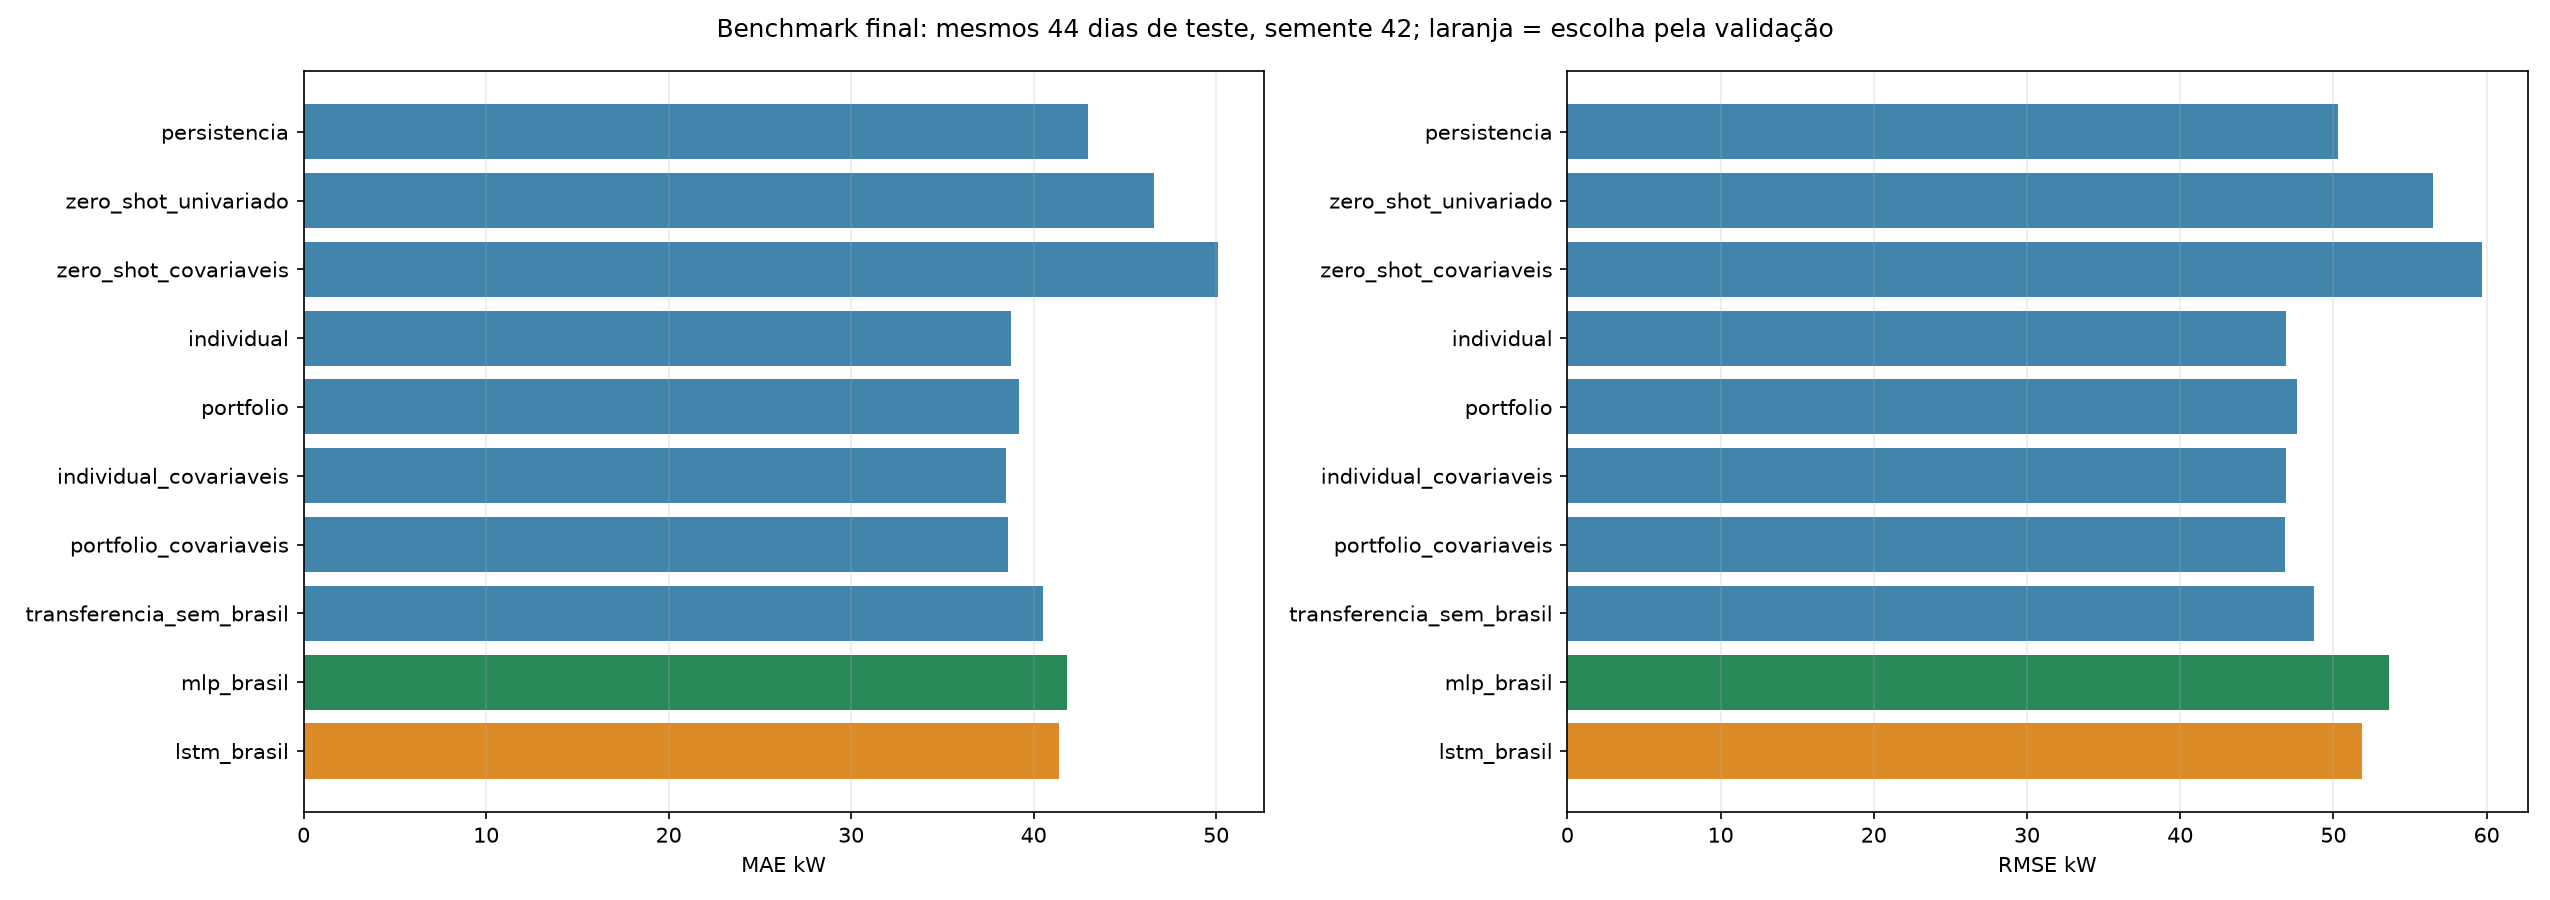

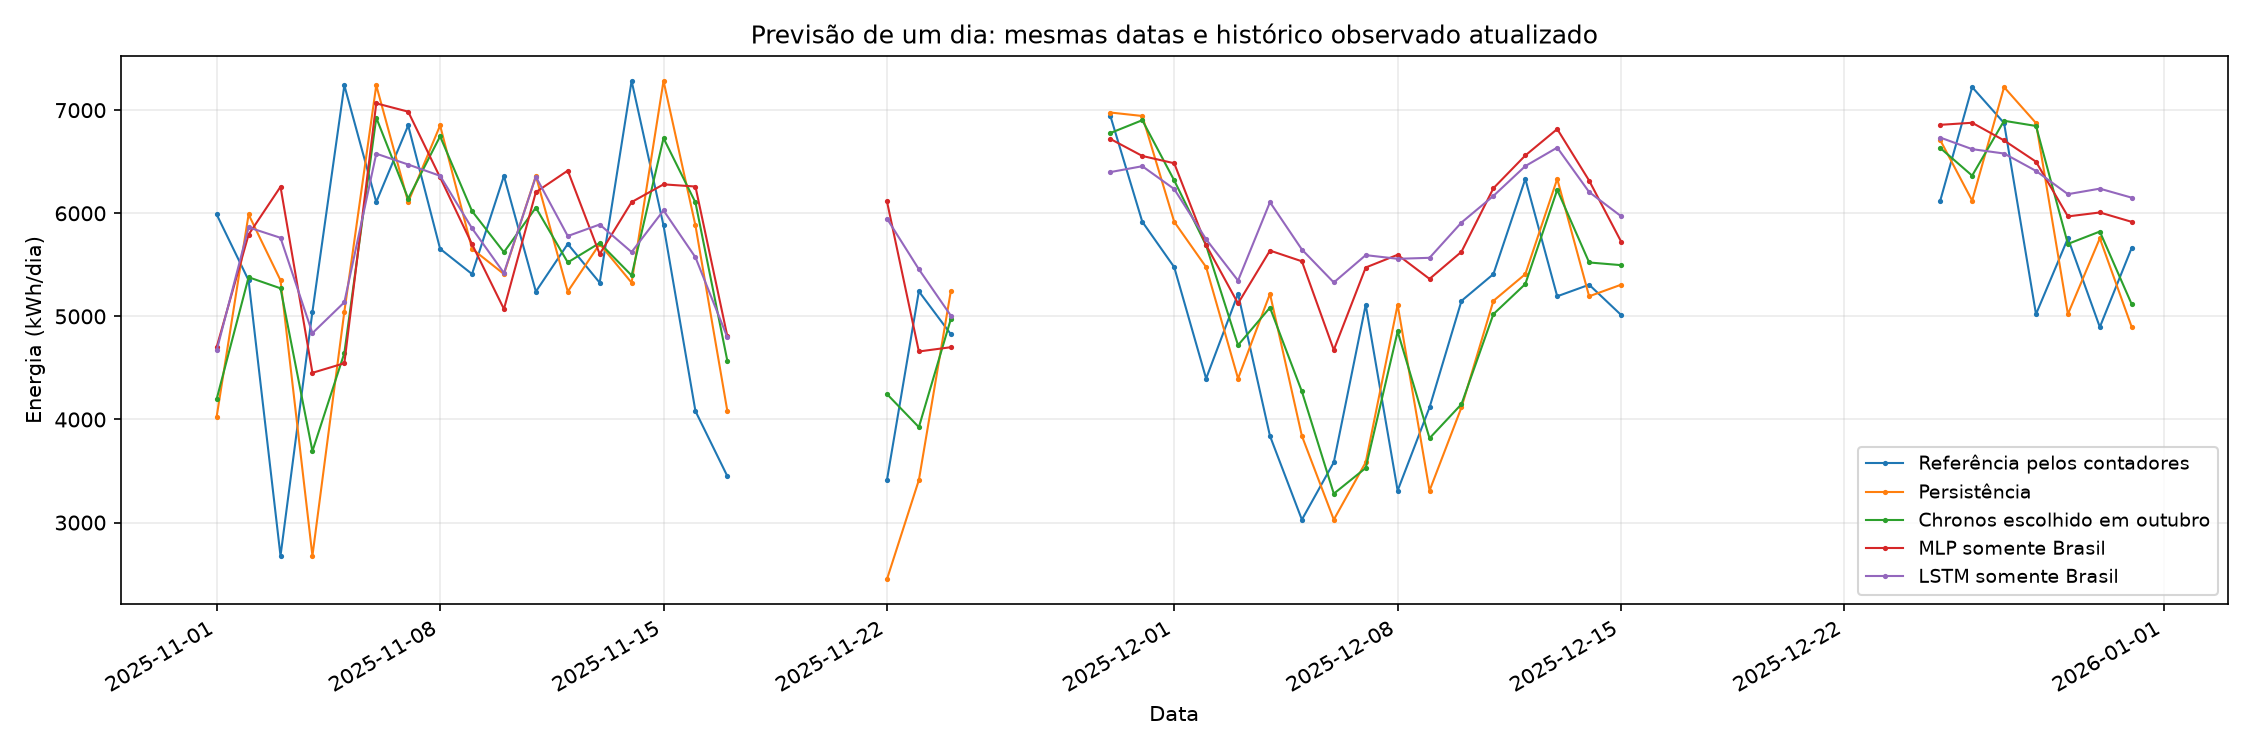

# Benchmark final diário — Brasil

MLP e LSTM treinadas do zero somente no Brasil; sem transferência e sem correção residual de persistência.
Mesmos 160 históricos de treino, 26 de validação e 44 de teste; três dias consecutivos para prever o dia seguinte.
Todas as redes recebem seis variáveis passadas e seno/cosseno conhecidos da data alvo. Sem vento e sem meteorologia futura observada.
Padronização de X/y ajustada somente no treino brasileiro. MLP 32/16 ReLU; LSTM de uma camada com 16 unidades e estado reiniciado a cada janela. Saída direta.
AdamW, taxa 0.001, weight decay 0.0001, lote 16, até 200 épocas, paciência 30. Checkpoint por MSE da validação de outubro.
Tabela principal: semente 42 previamente fixada, uma execução por modelo. Cinco sementes das redes locais são mostradas separadamente; seus desvios medem variação de inicialização, não intervalo de confiança nem significância estatística.
Os orçamentos e as perdas de treinamento diferem: redes locais usam MSE; Chronos usa LoRA e perda de quantis. Comparação dos erros na mesma referência brasileira.
O teste já foi consultado em estudos anteriores: resultado exploratório, sem confirmação independente.

Escolha pela validação conjunta: **lstm_brasil**.

| Modelo | N | MAE kW | RMSE kW | Skill RMSE % |
|---|---:|---:|---:|---:|
| persistencia | 44 | 42.961 | 50.301 | 0.000 |
| zero_shot_univariado | 44 | 46.585 | 56.510 | -12.345 |
| zero_shot_covariaveis | 44 | 50.104 | 59.684 | -18.655 |
| individual | 44 | 38.775 | 46.899 | 6.763 |
| portfolio | 44 | 39.191 | 47.601 | 5.367 |
| individual_covariaveis | 44 | 38.479 | 46.909 | 6.743 |
| portfolio_covariaveis | 44 | 38.610 | 46.811 | 6.938 |
| transferencia_sem_brasil | 44 | 40.537 | 48.721 | 3.141 |
| mlp_brasil | 44 | 41.824 | 53.623 | -6.605 |
| lstm_brasil | 44 | 41.410 | 51.885 | -3.150 |

## Variação entre cinco sementes (teste)

| Rede | Sementes | MAE médio kW | RMSE médio kW | Desvio RMSE kW |
|---|---:|---:|---:|---:|
| lstm_brasil | 5 | 40.607 | 51.288 | 1.914 |
| mlp_brasil | 5 | 41.250 | 52.572 | 2.291 |


In [ ]:
benchmark_final = pd.read_csv(RESULTADOS / 'benchmark_final.csv')
decisao_benchmark = json.loads((RESULTADOS / 'benchmark_decisao_validacao.json').read_text(encoding='utf-8'))
print('Escolha conjunta pelo RMSE na validação:', decisao_benchmark['escolhido']['modelo'])
print('Semente fixada para a comparação principal:', benchmark_config['seed_principal'])
assert benchmark_final.n.eq(44).all()
display(benchmark_final[['modelo', 'n', 'MAE_kW', 'RMSE_kW', 'WAPE_pct', 'Skill_RMSE_pct', 'MAE_kWh_dia', 'RMSE_kWh_dia', 'escolhido_validacao_geral']].round(3))
robustez = pd.read_csv(RESULTADOS / 'benchmark_robustez_seeds.csv')
display(robustez.round(3))
for figura in ['benchmark_comparacao_final.png', 'benchmark_previsoes_diarias.png']:
    display(Image(filename=str(RESULTADOS / figura)))
display(Markdown((RESULTADOS / 'benchmark_relatorio.md').read_text(encoding='utf-8')))


## 9. Diagnóstico dos 44 erros individuais e maiores desvios

Analisamos **o teste já congelado**, sem retreinar, selecionar modelos, alterar os alvos ou retirar os piores dias do benchmark. Há 44 resíduos por modelo e 440 resíduos no total dos dez métodos. Os gráficos destacam persistência, Chronos escolhido em outubro, MLP Brasil e LSTM Brasil, com a semente 42.

Definimos **erro = previsão − referência**: positivo significa superestimação; negativo, subestimação. O erro de energia em kWh/dia é 24 vezes o erro de potência média em kW. O erro absoluto mede o tamanho do desvio; o quadrático mostra quais dias mais contribuem para o RMSE.

A primeira tabela lista **todos os 44 dias**, a variação real em relação ao dia civil anterior e os resíduos dos modelos em foco. A segunda apresenta os cinco maiores desvios de cada um. O ranking de dias é apenas descritivo e não altera a escolha feita na validação.


Diagnóstico concluído: 44 dias, 10 modelos, 440 resíduos; sem retreino.
Erro = previsto − referência. Positivo = superestimação.
Limiar de mudança brusca (Q75 do treino): 54.753 kW
Dia com variação negativa abaixo do limiar: queda brusca; positiva acima do limiar: subida brusca.


<ipython-input-19-dd2536218bb0>:16: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(tabelas_erros['erros_por_dia'][colunas_44].round(3))
<ipython-input-19-dd2536218bb0>:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(maiores[maiores.modelo.isin(modelos_foco)][['modelo', 'timestamp', 'real_kw', 'previsto_kw', 'erro_kw', 'variacao_real_kw', 'regime', 'fracao_SSE_modelo_pct']].round(3))


,timestamp,referencia_diaria_kw,variacao_real_kw,regime,erro_persistencia_kw,erro_portfolio_covariaveis_kw,erro_mlp_brasil_kw,erro_lstm_brasil_kw
0,2025-11-01,249.517,81.663,subida_brusca,-81.663,-74.573,-53.587,-54.963
1,2025-11-02,222.908,-26.608,variacao_moderada,26.608,1.240,18.471,21.387
2,2025-11-03,111.521,-111.388,queda_brusca,111.388,108.147,149.183,128.569
3,2025-11-04,210.225,98.704,subida_brusca,-98.704,-56.336,-24.706,-8.666
4,2025-11-05,301.688,91.462,subida_brusca,-91.462,-108.188,-112.292,-87.645
5,2025-11-06,254.538,-47.150,variacao_moderada,47.150,34.080,39.892,19.550
6,2025-11-07,285.488,30.950,variacao_moderada,-30.950,-29.549,5.574,-15.790
7,2025-11-08,235.646,-49.842,variacao_moderada,49.842,45.456,28.861,29.489
8,2025-11-09,225.442,-10.204,variacao_moderada,10.204,25.449,12.063,18.487
9,2025-11-10,265.088,39.646,variacao_moderada,-39.646,-30.823,-53.782,-39.231


,modelo,timestamp,real_kw,previsto_kw,erro_kw,variacao_real_kw,regime,fracao_SSE_modelo_pct
398,lstm_brasil,2025-11-03,111.521,240.090,128.569,-111.388,queda_brusca,13.955
422,lstm_brasil,2025-12-05,126.171,235.358,109.187,-33.850,variacao_moderada,10.065
413,lstm_brasil,2025-11-22,142.171,247.861,105.690,40.092,variacao_moderada,9.430
421,lstm_brasil,2025-12-04,160.021,254.490,94.469,-57.429,queda_brusca,7.534
425,lstm_brasil,2025-12-08,137.904,231.604,93.700,-75.125,queda_brusca,7.412
354,mlp_brasil,2025-11-03,111.521,260.704,149.183,-111.388,queda_brusca,17.591
369,mlp_brasil,2025-11-22,142.171,254.827,112.656,40.092,variacao_moderada,10.031
356,mlp_brasil,2025-11-05,301.688,189.395,-112.292,91.462,subida_brusca,9.967
378,mlp_brasil,2025-12-05,126.171,230.592,104.421,-33.850,variacao_moderada,8.618
381,mlp_brasil,2025-12-08,137.904,233.220,95.316,-75.125,queda_brusca,7.181


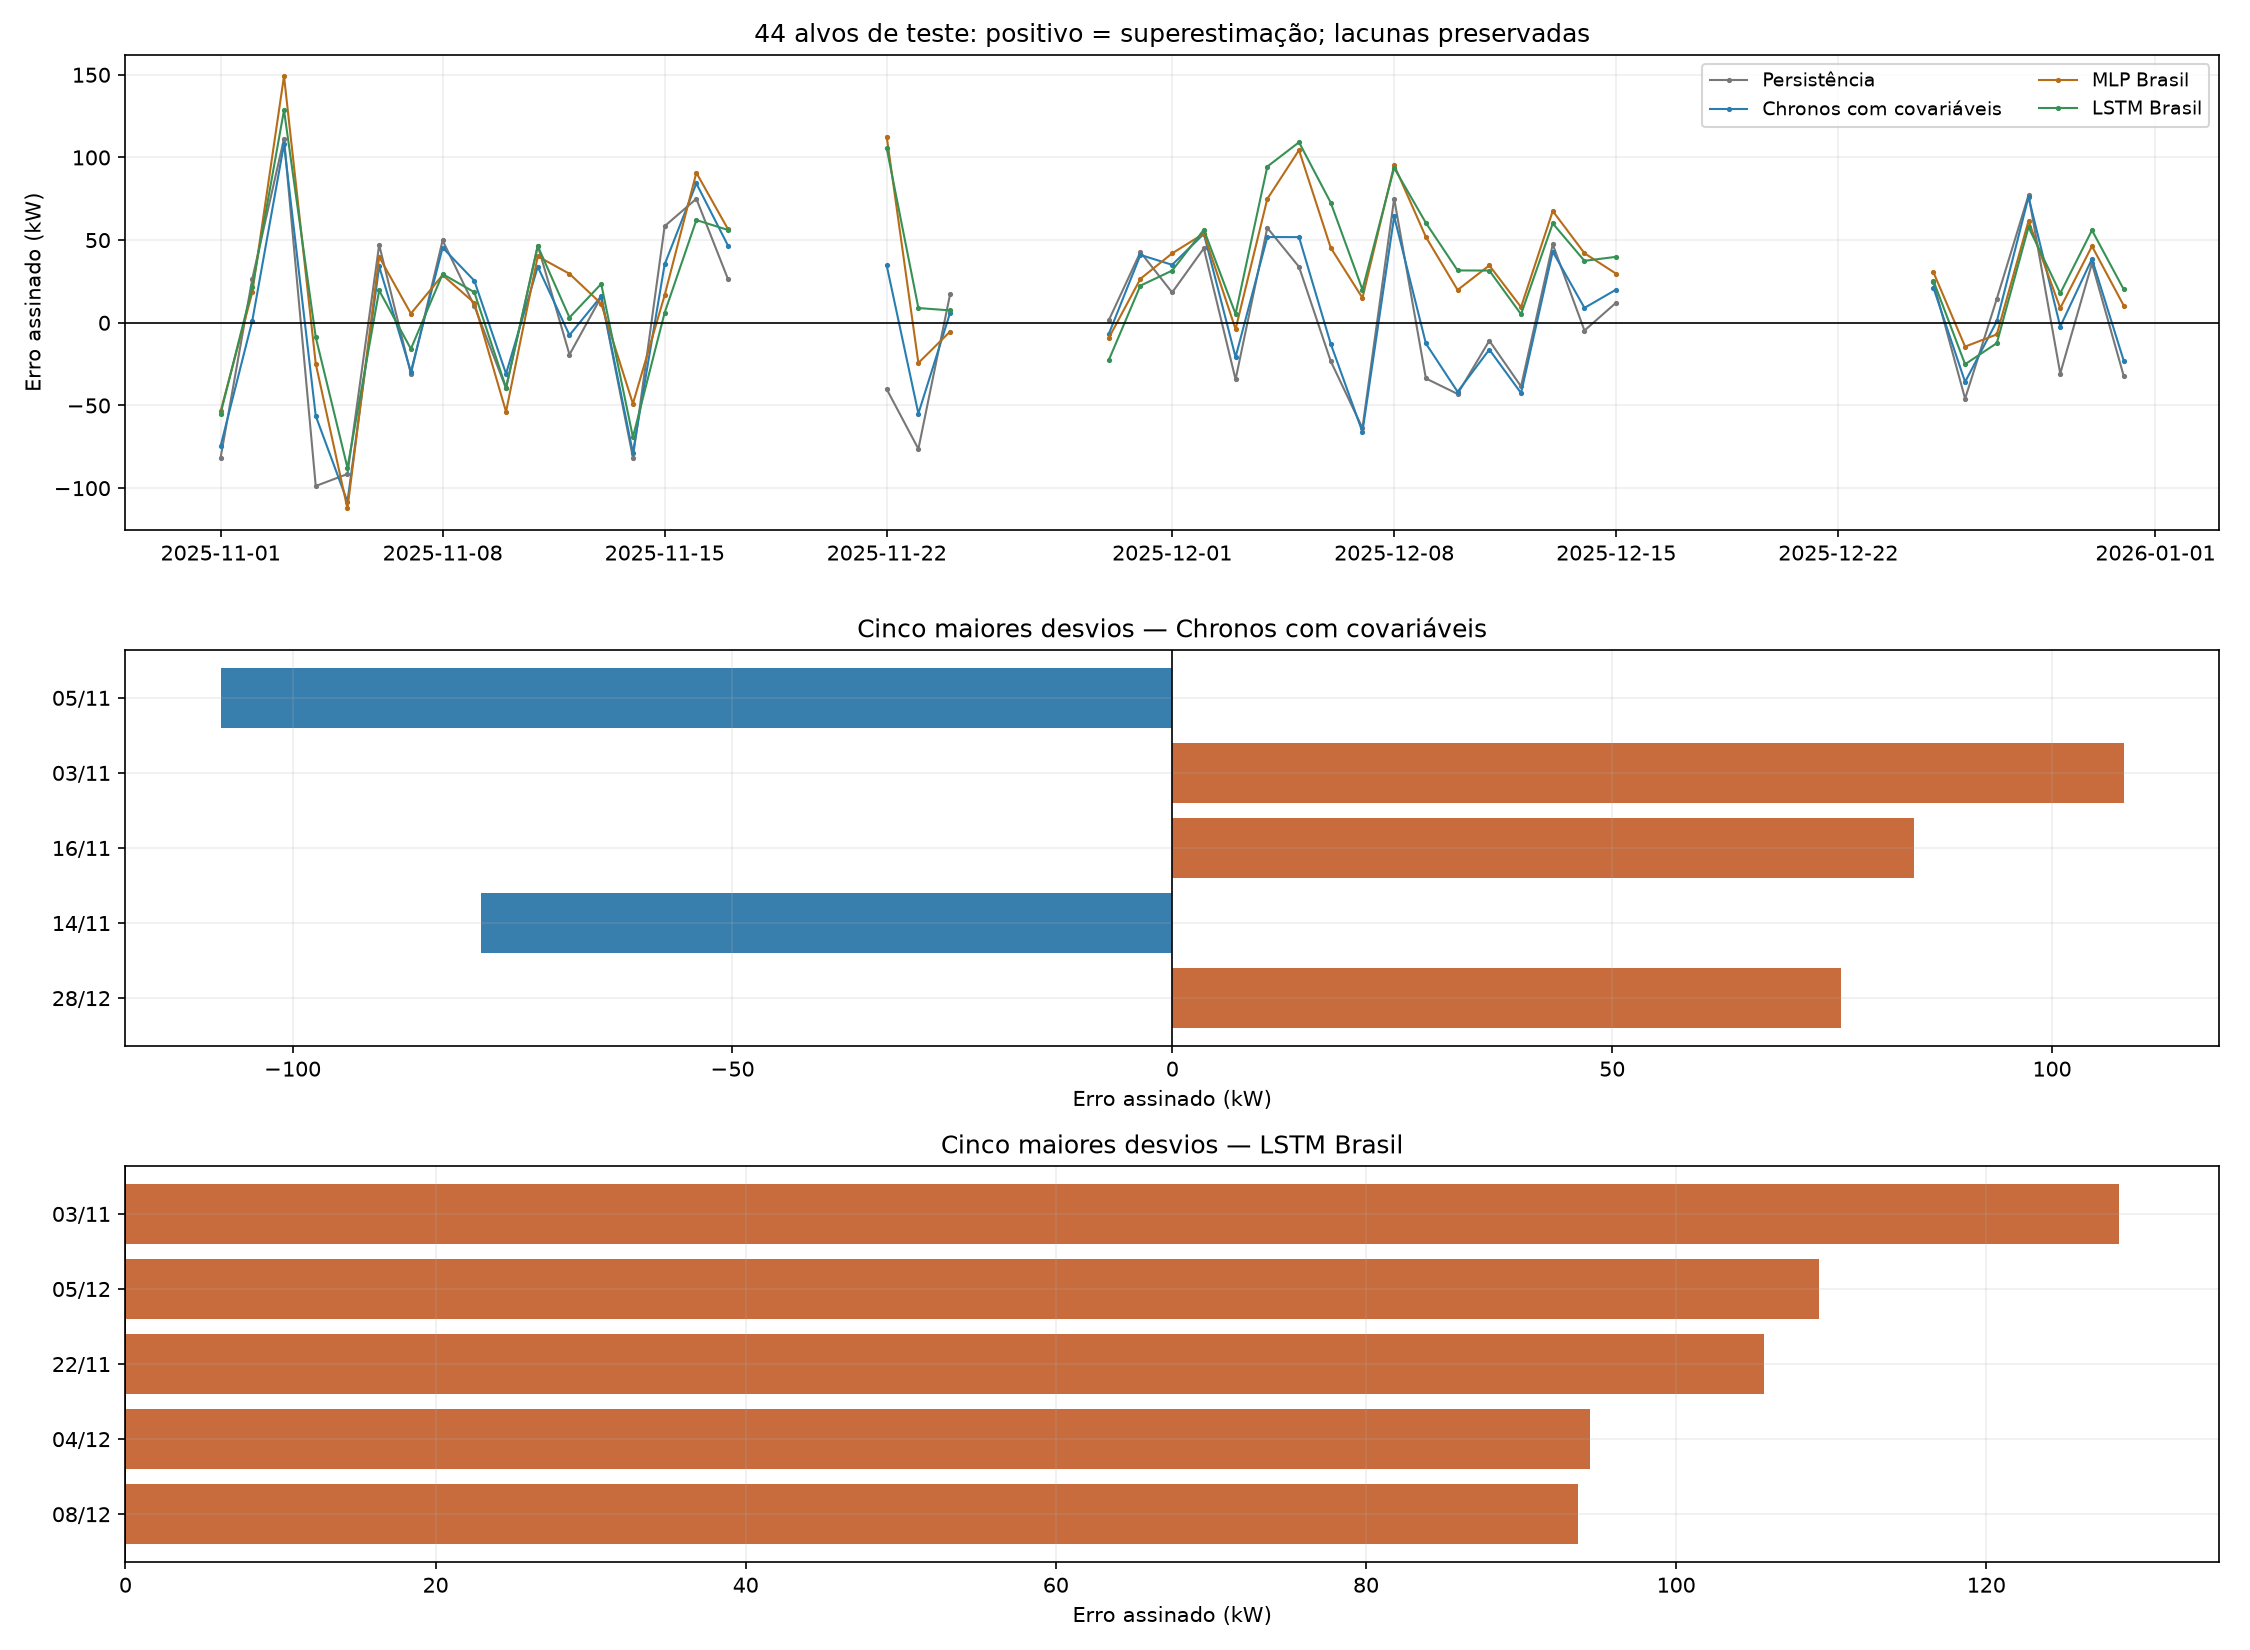

In [19]:
import importlib
from energia_transfer import diagnostico_erros_diarios
importlib.reload(diagnostico_erros_diarios)
from energia_transfer.diagnostico_erros_diarios import analisar_erros

diagnostico = analisar_erros(RAIZ)
DIAGNOSTICO = diagnostico['out']
tabelas_erros = diagnostico['tabelas']
modelos_foco = diagnostico['foco']
limiar_brusco = diagnostico['meta']['limiar_principal_kw']
print('Erro = previsto − referência. Positivo = superestimação.')
print('Limiar de mudança brusca (Q75 do treino):', round(limiar_brusco, 3), 'kW')
print('Dia com variação negativa abaixo do limiar: queda brusca; positiva acima do limiar: subida brusca.')
colunas_44 = ['timestamp', 'referencia_diaria_kw', 'variacao_real_kw', 'regime'] + [f'erro_{m}_kw' for m in modelos_foco]
with pd.option_context('display.max_rows', 60, 'display.max_columns', 12):
    display(tabelas_erros['erros_por_dia'][colunas_44].round(3))
maiores = tabelas_erros['maiores_desvios']
display(maiores[maiores.modelo.isin(modelos_foco)][['modelo', 'timestamp', 'real_kw', 'previsto_kw', 'erro_kw', 'variacao_real_kw', 'regime', 'fracao_SSE_modelo_pct']].round(3))
display(Image(filename=str(DIAGNOSTICO / 'erros_individuais_e_maiores.png')))


## 10. Distribuição dos resíduos e concentração em poucos dias

Comparamos viés, mediana, dispersão, percentis 90/95 do erro absoluto e extremos. Os histogramas usam as mesmas faixas; o boxplot e a distribuição empírica não pressupõem normalidade.

Na curva de concentração, ordenamos os dias do maior para o menor erro quadrático. Se todos tivessem a mesma magnitude, **cinco dos 44 dias responderiam por 11,36%** do total. Uma contribuição maior revela concentração, sem constituir um teste estatístico de uniformidade. O Gini descreve desigualdade entre magnitudes dos erros; não é uma medida de qualidade dos alvos.


,modelo,n,MAE_kw,RMSE_kw,BIAS_kw,mediana_erro_kw,P90_absoluto_kw,P95_absoluto_kw,max_absoluto_kw,top5_SSE_pct,top10_SSE_pct,gini_erro_absoluto,superestimacoes,subestimacoes
0,persistencia,44,42.961,50.301,1.144,11.202,80.253,89.993,111.388,39.373,63.724,0.339,24,20
6,portfolio_covariaveis,44,38.610,46.811,5.857,7.511,75.618,83.464,108.188,44.057,65.045,0.380,25,19
8,mlp_brasil,44,41.824,53.623,25.572,27.731,93.946,111.112,149.183,53.388,73.470,0.427,33,11
9,lstm_brasil,44,41.410,51.885,26.160,22.984,91.883,104.007,128.569,48.396,69.721,0.411,35,9


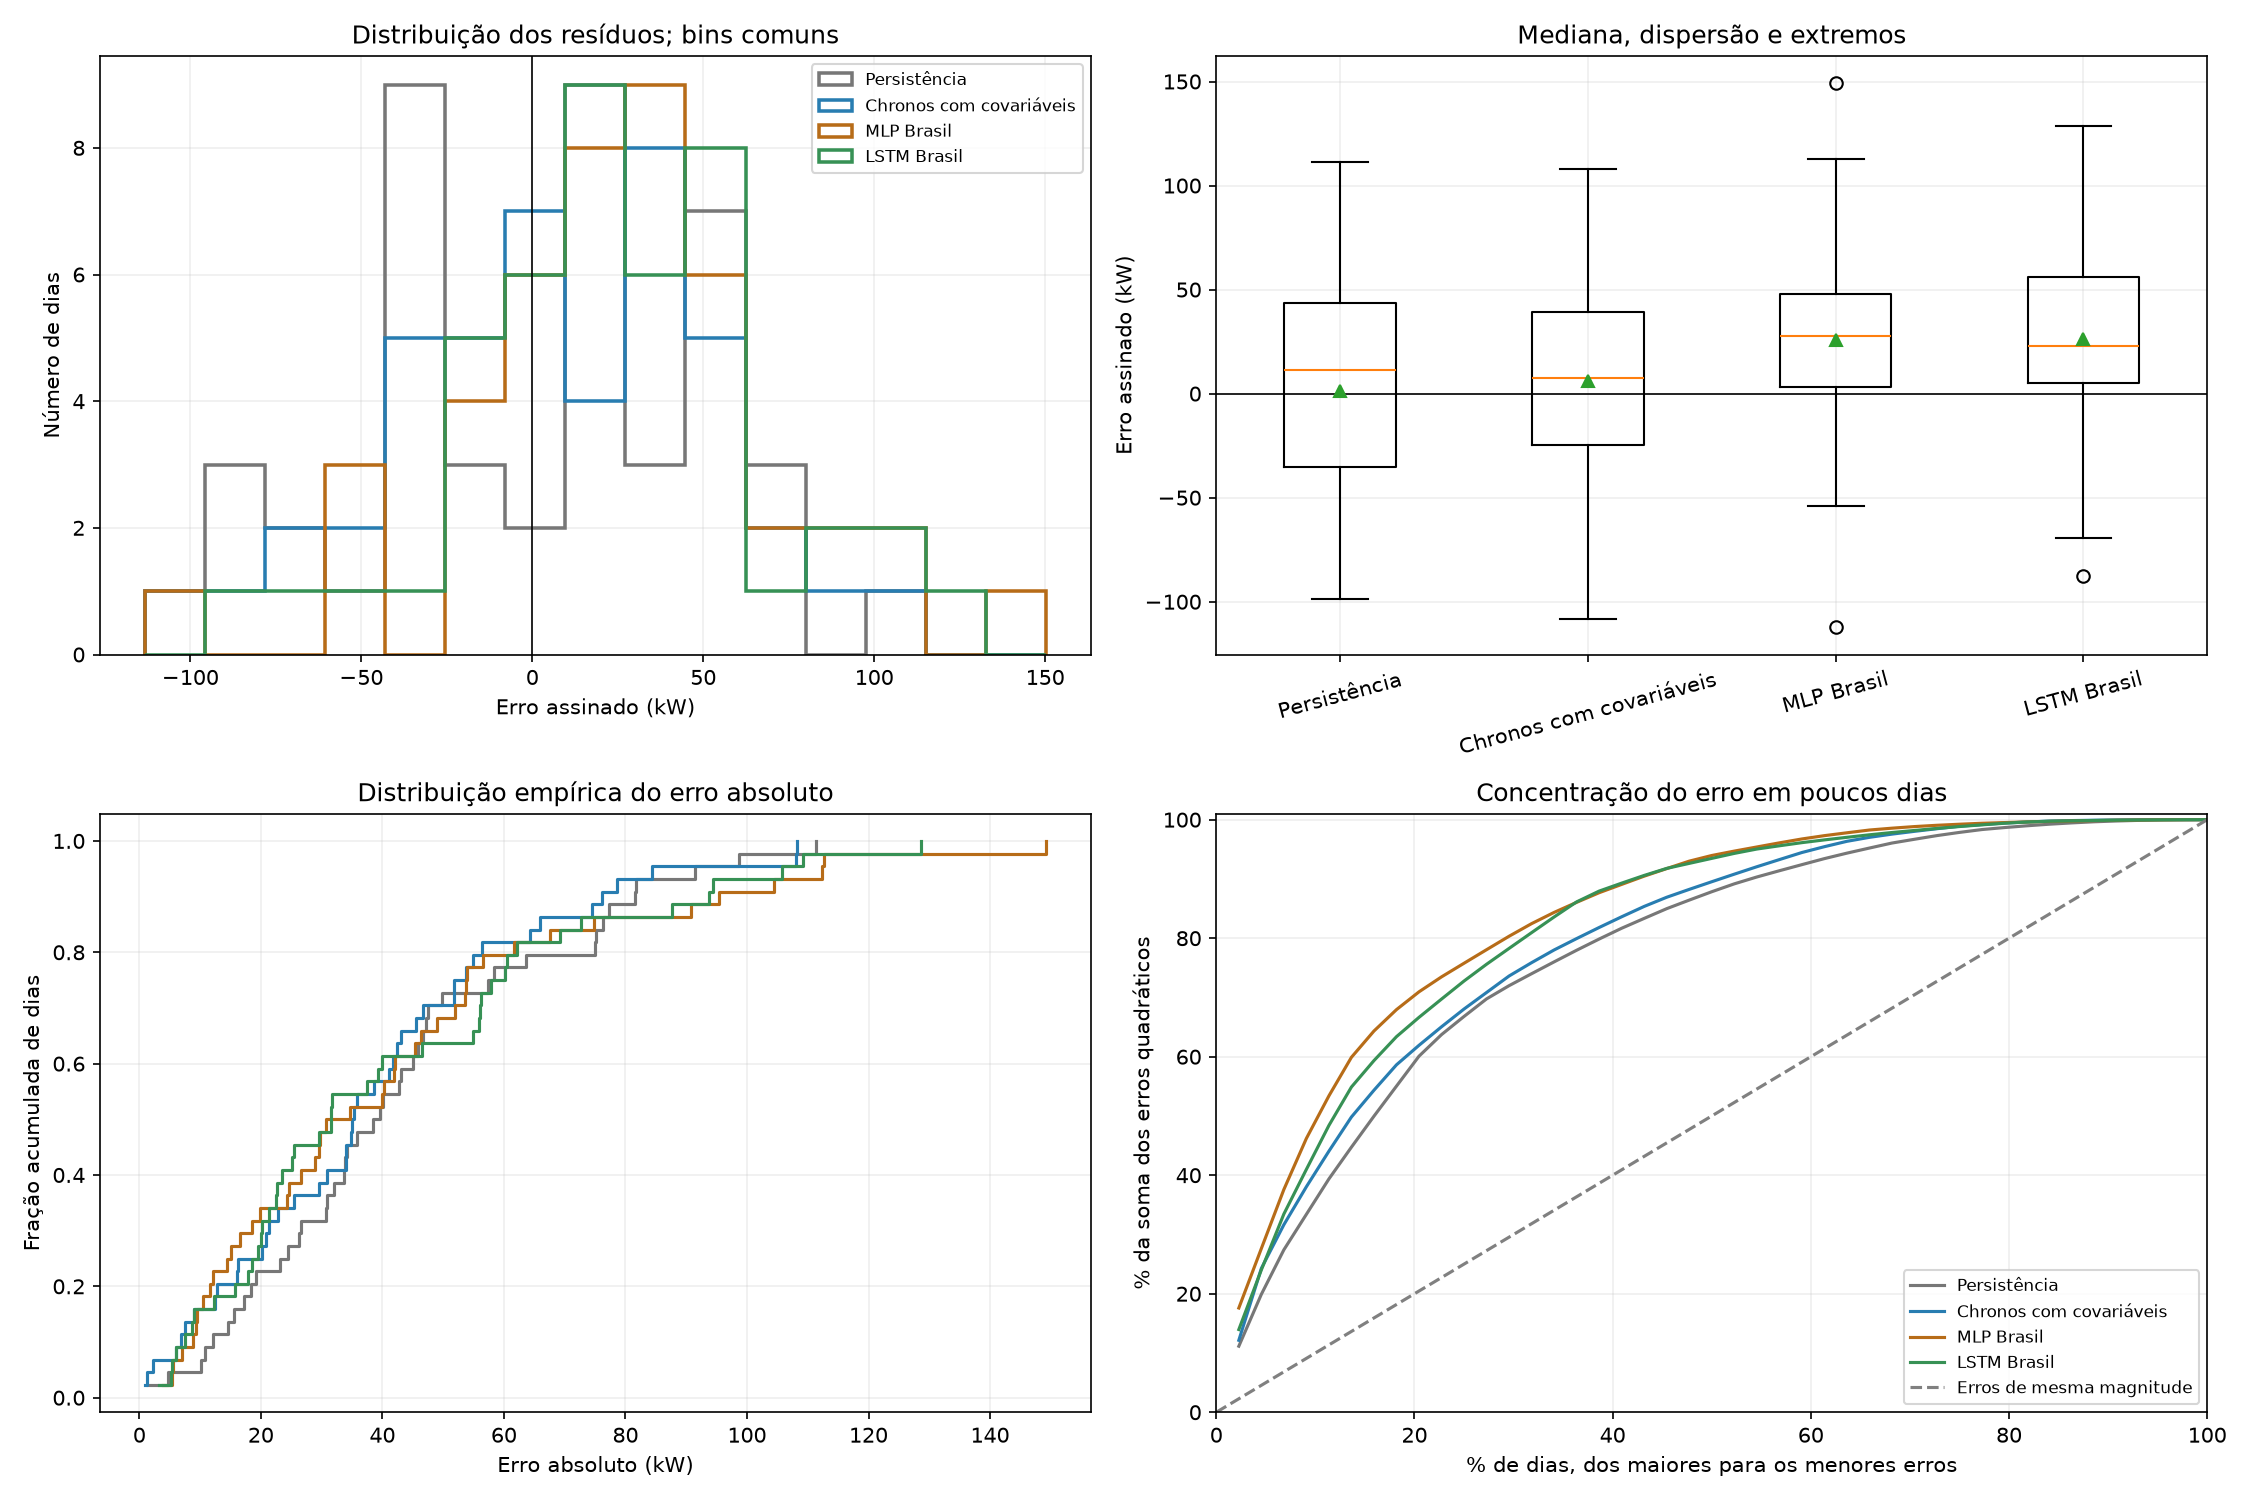

In [20]:
distribuicao = tabelas_erros['resumo_distribuicao']
display(distribuicao[distribuicao.modelo.isin(modelos_foco)][[
    'modelo', 'n', 'MAE_kw', 'RMSE_kw', 'BIAS_kw', 'mediana_erro_kw',
    'P90_absoluto_kw', 'P95_absoluto_kw', 'max_absoluto_kw',
    'top5_SSE_pct', 'top10_SSE_pct', 'gini_erro_absoluto', 'superestimacoes', 'subestimacoes'
]].round(3))
display(Image(filename=str(DIAGNOSTICO / 'distribuicao_e_concentracao.png')))


## 11. Diferenças entre meses, quedas e subidas bruscas

O limite principal de mudança brusca é o **percentil 75 das variações absolutas diárias do treino**, calculado somente até setembro, com pares de dias civis consecutivos e aprovados. Não conectamos dias separados por lacunas. O percentil 90 do mesmo treino fornece uma análise de sensibilidade; não ajustamos nenhum limite pelos erros de teste.

As categorias são queda brusca, variação moderada e subida brusca. Reportamos o número de dias, MAE, viés e contribuição para a soma dos erros quadráticos (SSE). A razão entre fração do SSE e fração dos dias indica concentração: acima de 1 significa mais erro quadrático por dia naquele regime.

**O erro e a variação observada compartilham o alvo.** Para persistência, erro = −variação por definição. Assim, correlação entre essas grandezas não demonstra causalidade nem comprova que faltou uma variável explicativa.

Há 22 alvos avaliados em cada mês, selecionados entre 61 dias do bimestre. As diferenças descrevem esses recortes e sua composição de mudanças; não representam os dias reprovados nem comprovam sazonalidade.


Análise principal: Q75 do treino
Sensibilidade: Q90 do treino — observar o número pequeno de eventos


,mes,dias_calendario,dias_contadores_validos,alvos_avaliados,media_real_kw,media_variacao_absoluta_kw,quedas_bruscas,subidas_bruscas,media_ghi_alvos_wm2,media_fracao_leituras_pct
0,2025-11,30,28,22,227.271,49.471,3,5,258.718,93.265
1,2025-12,31,25,22,212.228,36.451,3,1,228.250,93.174


,modelo,mes,n,MAE_kw,RMSE_kw,BIAS_kw,Skill_RMSE_pct
0,persistencia,2025-11,22,49.471,57.985,-1.401,0.000
1,persistencia,2025-12,22,36.451,41.208,3.688,0.000
12,portfolio_covariaveis,2025-11,22,43.624,53.085,2.958,8.449
13,portfolio_covariaveis,2025-12,22,33.596,39.553,8.755,4.017
16,mlp_brasil,2025-11,22,44.127,58.394,13.925,-0.706
17,mlp_brasil,2025-12,22,39.521,48.383,37.220,-17.413
18,lstm_brasil,2025-11,22,38.986,51.356,11.883,11.431
19,lstm_brasil,2025-12,22,43.835,52.409,40.436,-27.182


,modelo,quantil_treino,limiar_kw,regime,n,MAE_kw,BIAS_kw,fracao_dias_pct,fracao_SSE_pct,concentracao_SSE_por_fracao_dias
0,persistencia,75,54.753,queda_brusca,6,75.770,75.770,13.636,32.657,2.395
1,persistencia,75,54.753,variacao_moderada,32,29.448,2.782,72.727,30.247,0.416
2,persistencia,75,54.753,subida_brusca,6,82.219,-82.219,13.636,37.096,2.720
36,portfolio_covariaveis,75,54.753,queda_brusca,6,69.995,69.995,13.636,33.875,2.484
37,portfolio_covariaveis,75,54.753,variacao_moderada,32,26.259,8.634,72.727,30.877,0.425
38,portfolio_covariaveis,75,54.753,subida_brusca,6,73.094,-73.094,13.636,35.248,2.585
48,mlp_brasil,75,54.753,queda_brusca,6,81.401,81.401,13.636,38.936,2.855
49,mlp_brasil,75,54.753,variacao_moderada,32,33.529,27.675,72.727,45.803,0.630
50,mlp_brasil,75,54.753,subida_brusca,6,46.486,-41.468,13.636,15.260,1.119
54,lstm_brasil,75,54.753,queda_brusca,6,73.813,73.813,13.636,35.023,2.568


,modelo,quantil_treino,limiar_kw,regime,n,MAE_kw,BIAS_kw,fracao_dias_pct,fracao_SSE_pct,concentracao_SSE_por_fracao_dias
3,persistencia,90,88.763,queda_brusca,1,111.388,111.388,2.273,11.145,4.904
4,persistencia,90,88.763,variacao_moderada,41,38.749,3.149,93.182,72.590,0.779
5,persistencia,90,88.763,subida_brusca,2,95.083,-95.083,4.545,16.266,3.578
39,portfolio_covariaveis,90,88.763,queda_brusca,1,108.147,108.147,2.273,12.131,5.338
40,portfolio_covariaveis,90,88.763,variacao_moderada,41,34.784,7.660,93.182,72.437,0.777
41,portfolio_covariaveis,90,88.763,subida_brusca,2,82.262,-82.262,4.545,15.432,3.395
51,mlp_brasil,90,88.763,queda_brusca,1,149.183,149.183,2.273,17.591,7.740
52,mlp_brasil,90,88.763,variacao_moderada,41,37.904,27.146,93.182,71.960,0.772
53,mlp_brasil,90,88.763,subida_brusca,2,68.499,-68.499,4.545,10.449,2.299
57,lstm_brasil,90,88.763,queda_brusca,1,128.569,128.569,2.273,13.955,6.140


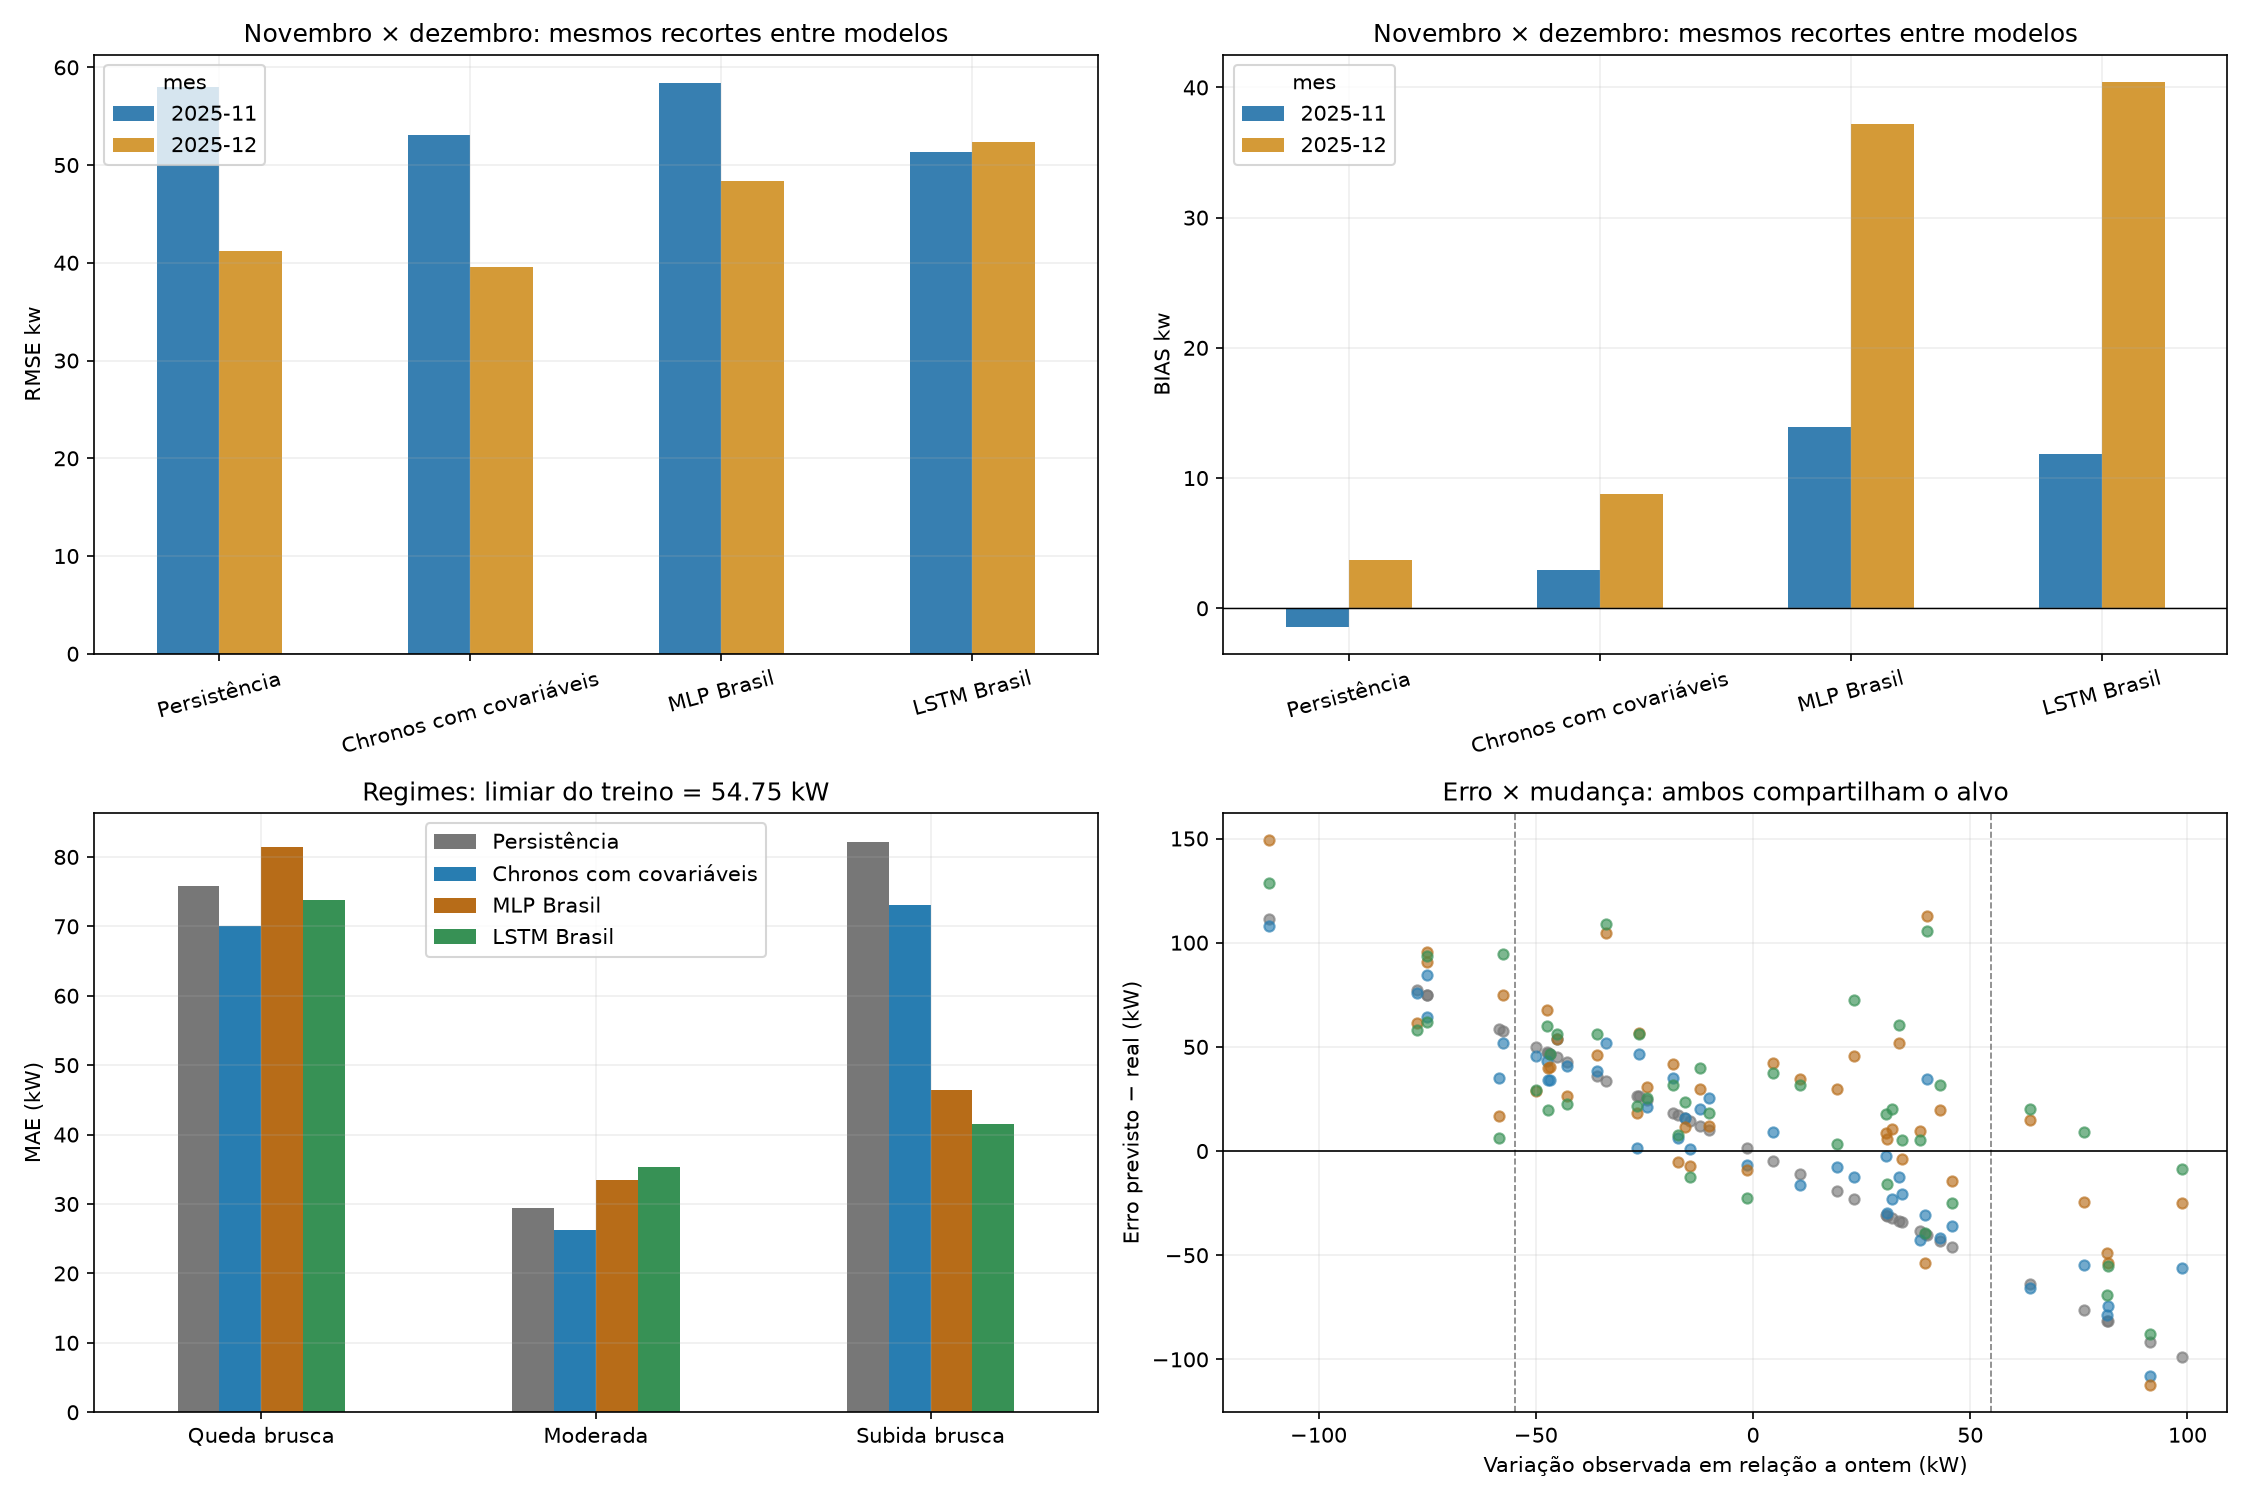

In [21]:
display(tabelas_erros['contexto_mensal'].round(3))
mensais = tabelas_erros['metricas_mensais']
display(mensais[mensais.modelo.isin(modelos_foco)][['modelo', 'mes', 'n', 'MAE_kw', 'RMSE_kw', 'BIAS_kw', 'Skill_RMSE_pct']].round(3))
regimes = tabelas_erros['metricas_por_regime']
col_regimes = ['modelo', 'quantil_treino', 'limiar_kw', 'regime', 'n', 'MAE_kw', 'BIAS_kw', 'fracao_dias_pct', 'fracao_SSE_pct', 'concentracao_SSE_por_fracao_dias']
print('Análise principal: Q75 do treino')
display(regimes[regimes.modelo.isin(modelos_foco) & regimes.quantil_treino.eq(75)][col_regimes].round(3))
print('Sensibilidade: Q90 do treino — observar o número pequeno de eventos')
display(regimes[regimes.modelo.isin(modelos_foco) & regimes.quantil_treino.eq(90)][col_regimes].round(3))
display(Image(filename=str(DIAGNOSTICO / 'meses_e_mudancas_bruscas.png')))


## 12. Qualidade dos alvos e meteorologia no diagnóstico

Todos os 44 alvos passaram na conferência dos oito inversores. Cruzamos a magnitude dos resíduos com a diferença entre os contadores e com a fração de leituras de potência disponíveis. Essa fração usa **8 × 288 = 2304 registros inversor-horário possíveis**; não é a fração de horários com a planta inteira simultaneamente medida. Um contador completo pode conservar a energia mesmo sem telemetria contínua de potência.

Como sensibilidade, trocamos apenas a referência pela soma das diferenças do contador acumulado, dividida por 24. **Mantemos todas as previsões originais, inclusive a persistência**, e não retreinamos. Os dois contadores vêm dos mesmos equipamentos; sua concordância não equivale a uma referência independente nem exclui erro comum de calibração.

O GHI do próprio dia alvo e sua variação em relação a ontem aparecem **somente para explicação retrospectiva**. Essas observações futuras não foram fornecidas aos modelos. As correlações de postos são descritivas, sujeitas ao tamanho da amostra, dependência temporal, fatores comuns e seleção dos alvos. Não identificam sozinhas a causa dos erros.

Distinguimos duas correlações: erro **absoluto** × mudança **absoluta** do GHI, e erro **assinado** × mudança **assinada** do GHI. Uma associação fraca entre magnitudes pode coexistir com uma associação direcional entre superestimação e redução de radiação.


Maior diferença entre referências: 0.1292 kW


,fracao_leituras_potencia_pct,menor_cobertura_inversor_pct,max_diferenca_inversor_kwh,diferenca_referencias_kw
count,44.0000,44.0000,44.0000,44.0000
mean,93.2193,93.1029,0.6659,0.0044
std,4.4115,4.3912,0.1430,0.0533
min,73.2639,73.2639,0.3000,-0.1042
25%,93.7500,93.7500,0.6000,-0.0333
50%,95.0955,94.7917,0.7000,-0.0042
75%,95.1389,95.1389,0.8000,0.0427
max,95.4861,95.4861,0.9000,0.1292


,modelo,n,RMSE_referencia_diario_kw,RMSE_referencia_acumulado_kw,MAE_referencia_diario_kw,MAE_referencia_acumulado_kw
0,persistencia,44,50.3005,50.2994,42.9609,42.9582
6,portfolio_covariaveis,44,46.8106,46.8094,38.6097,38.6078
8,mlp_brasil,44,53.6227,53.6257,41.8242,41.8214
9,lstm_brasil,44,51.8853,51.8859,41.4104,41.4072


,modelo,indicador,tipo_erro,rho_spearman_descritivo,n
0,persistencia,abs_variacao_real_kw,absoluto,1.000,44
1,persistencia,abs_variacao_ghi_wm2,absoluto,0.216,44
2,persistencia,fracao_leituras_potencia_pct,absoluto,-0.020,44
3,persistencia,max_diferenca_inversor_kwh,absoluto,0.132,44
4,persistencia,variacao_ghi_wm2,assinado,-0.506,44
30,portfolio_covariaveis,abs_variacao_real_kw,absoluto,0.853,44
31,portfolio_covariaveis,abs_variacao_ghi_wm2,absoluto,0.191,44
32,portfolio_covariaveis,fracao_leituras_potencia_pct,absoluto,0.001,44
33,portfolio_covariaveis,max_diferenca_inversor_kwh,absoluto,0.043,44
34,portfolio_covariaveis,variacao_ghi_wm2,assinado,-0.576,44


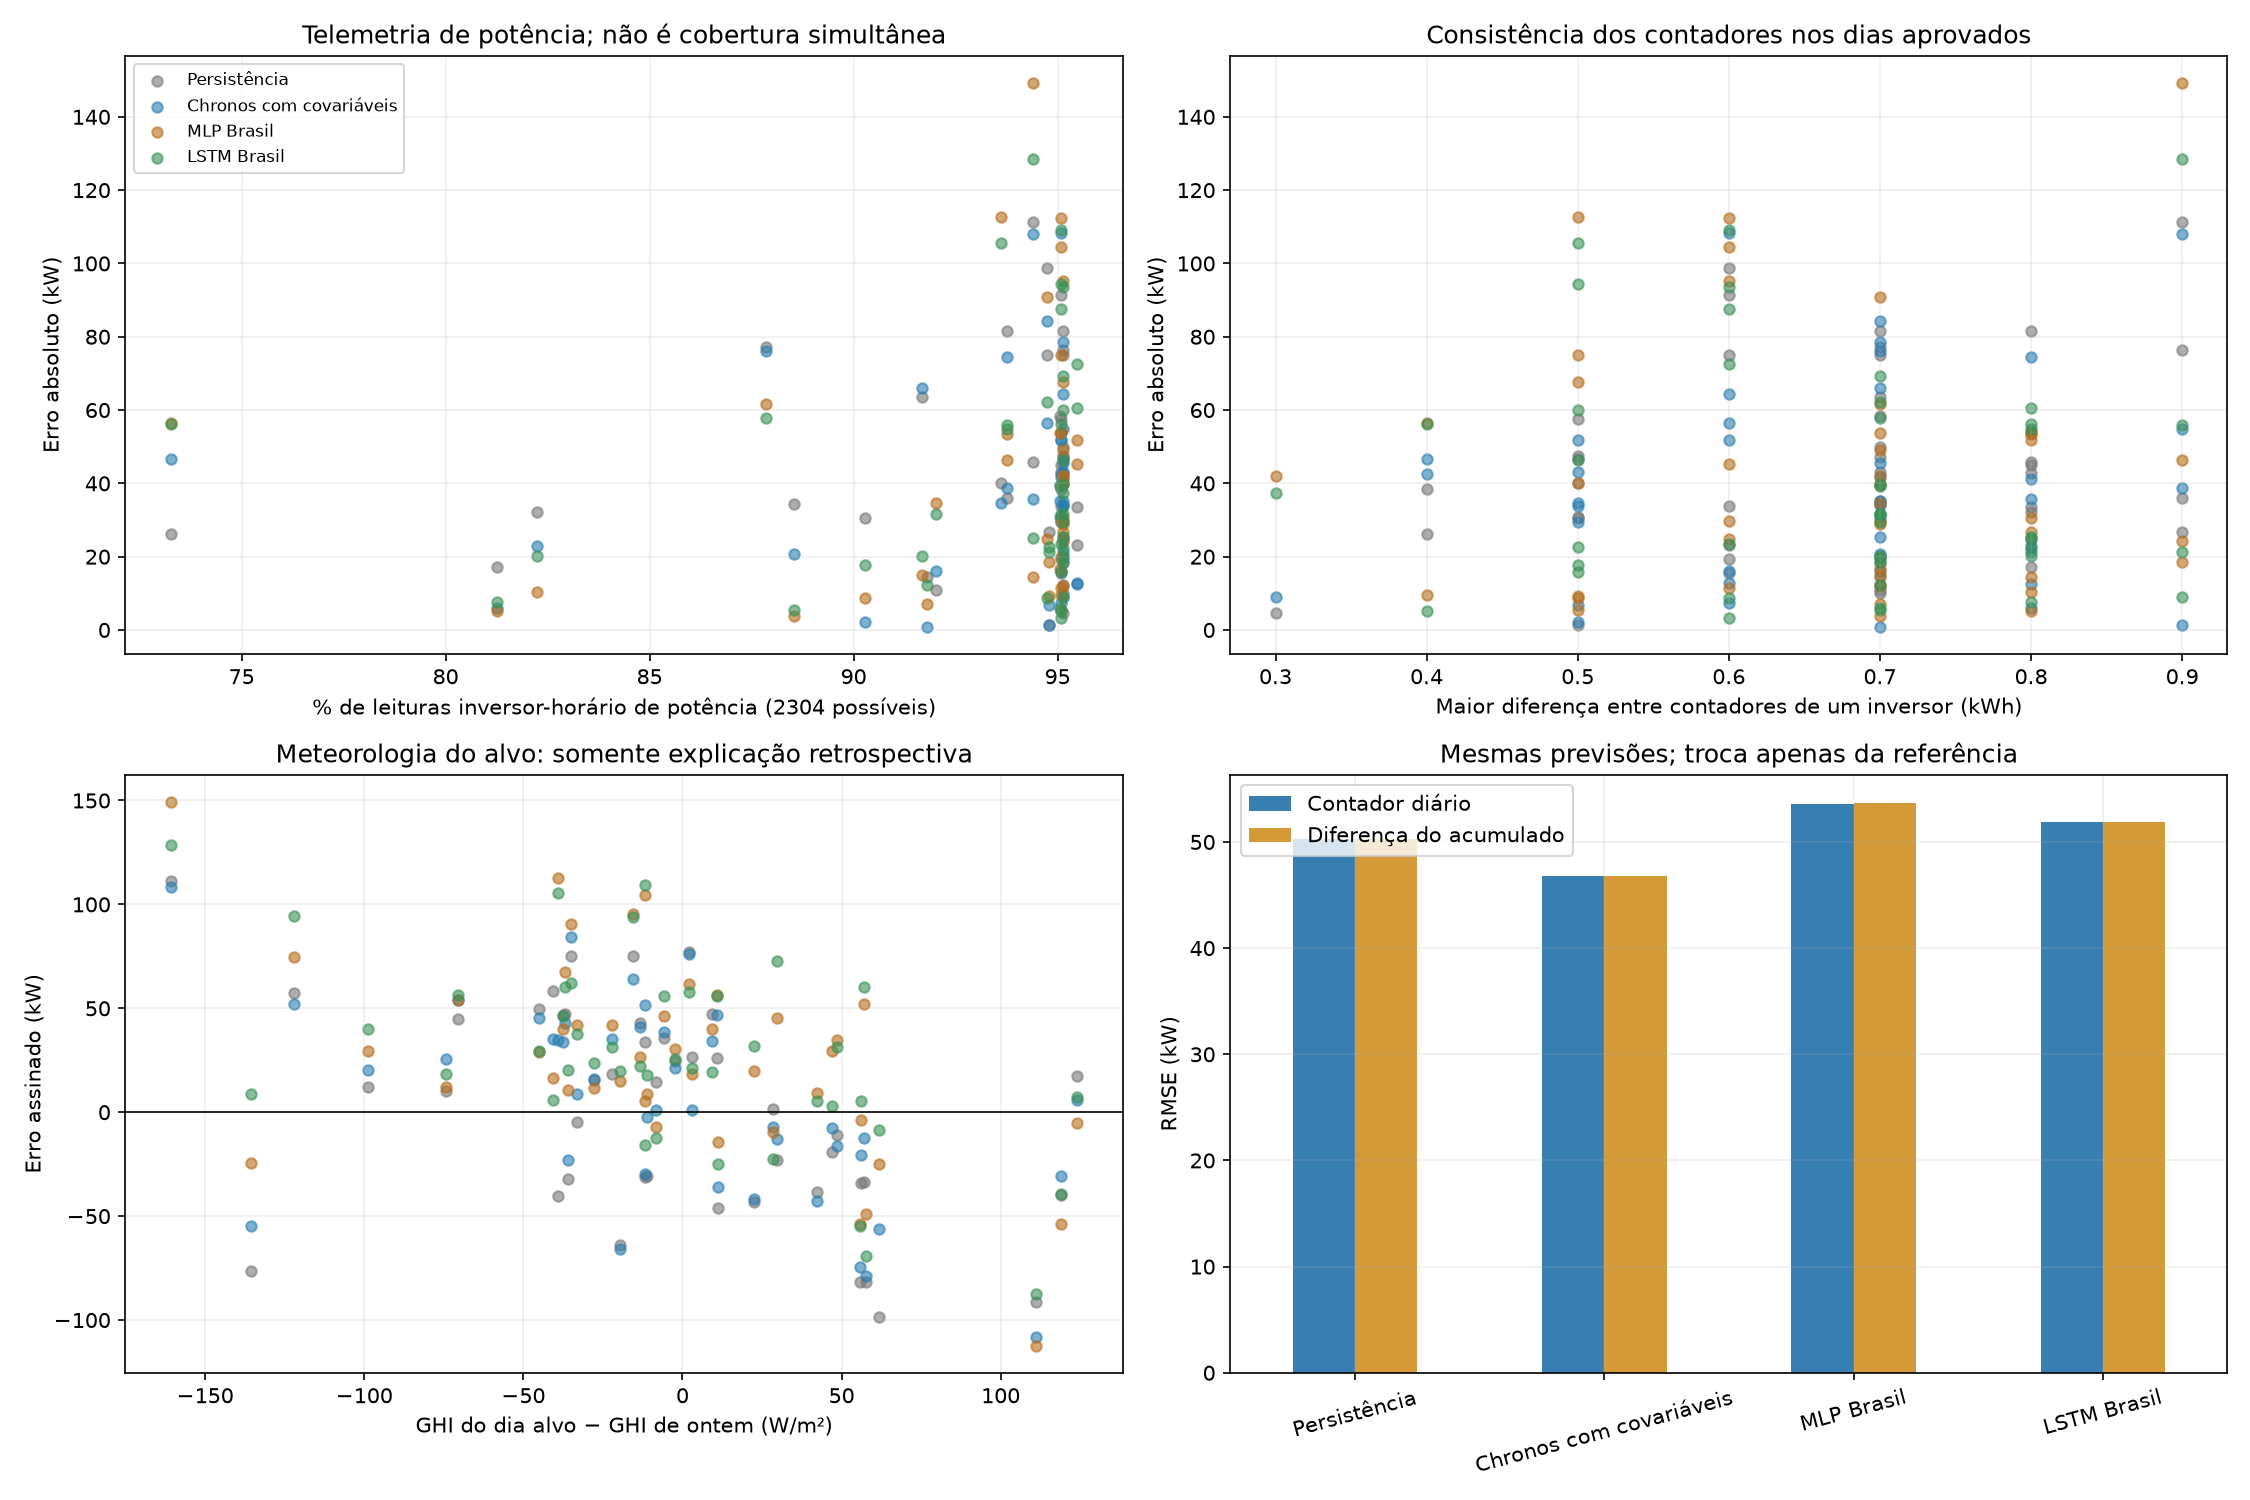

In [22]:
q44 = tabelas_erros['erros_por_dia']
print('Maior diferença entre referências:', round(q44.diferenca_referencias_kw.abs().max(), 4), 'kW')
display(q44[['fracao_leituras_potencia_pct', 'menor_cobertura_inversor_pct', 'max_diferenca_inversor_kwh', 'diferenca_referencias_kw']].describe().round(4))
sensibilidade = tabelas_erros['sensibilidade_referencia']
display(sensibilidade[sensibilidade.modelo.isin(modelos_foco)].round(4))
correlacoes = tabelas_erros['correlacoes_descritivas']
display(correlacoes[correlacoes.modelo.isin(modelos_foco)].round(3))
display(Image(filename=str(DIAGNOSTICO / 'qualidade_e_meteorologia.png')))


## 13. Síntese e limites da interpretação

O relatório abaixo reúne os maiores desvios, a concentração dos resíduos, a comparação mensal e a sensibilidade à referência. Ele ajuda a separar evidências de:

- dificuldade com mudanças rápidas, incluindo quedas e subidas;
- viés de superestimação e generalização dos modelos locais;
- consistência interna dos contadores e limitações dos indicadores de qualidade disponíveis.

Nenhum desses indicadores, isoladamente, identifica a causa dos erros. Não excluímos os piores dias para melhorar métricas. Uma alteração do modelo motivada por este diagnóstico precisará de nova avaliação temporal independente.

Tabelas completas, figuras, relatório e hashes das fontes ficam em `experimentos/chronos_diario_contadores/resultados/diagnostico_erros/`. A análise confere que as previsões e as decisões originais permanecem inalteradas.


In [23]:
display(Markdown((DIAGNOSTICO / 'analise_erros.md').read_text(encoding='utf-8')))
print('Arquivos do diagnóstico:', DIAGNOSTICO)


Arquivos do diagnóstico: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\experimentos\chronos_diario_contadores\resultados\diagnostico_erros


# Diagnóstico dos 44 erros diários

Erro = previsto − referência. Positivo indica superestimação; energia diária tem erro 24 vezes o erro em potência média.
Analisados 44 dias e 10 métodos (440 resíduos), sem alterar previsões, hiperparâmetros ou decisões.
Modelos em foco: persistência, Chronos escolhido pela validação, MLP Brasil e LSTM Brasil (semente 42).

## Distribuição e concentração

| Modelo | MAE kW | RMSE kW | Viés kW | P90 absoluto kW | Top 5: % do erro quadrático |
|---|---:|---:|---:|---:|---:|
| Persistência | 42.96 | 50.30 | 1.14 | 80.25 | 39.4 |
| Chronos com covariáveis | 38.61 | 46.81 | 5.86 | 75.62 | 44.1 |
| MLP Brasil | 41.82 | 53.62 | 25.57 | 93.95 | 53.4 |
| LSTM Brasil | 41.41 | 51.89 | 26.16 | 91.88 | 48.4 |

Se todos os erros tivessem a mesma magnitude, cinco dos 44 dias responderiam por 11,36% da soma de erros quadráticos. A curva de concentração é descritiva, sem teste de uniformidade ou normalidade.

## Dias com maiores desvios

| Modelo | Dia | Variação real kW | Erro kW | Regime |
|---|---|---:|---:|---|
| Persistência | 03/11/2025 | -111.39 | 111.39 | queda_brusca |
| Persistência | 04/11/2025 | 98.70 | -98.70 | subida_brusca |
| Persistência | 05/11/2025 | 91.46 | -91.46 | subida_brusca |
| Persistência | 01/11/2025 | 81.66 | -81.66 | subida_brusca |
| Persistência | 14/11/2025 | 81.54 | -81.54 | subida_brusca |
| Chronos com covariáveis | 05/11/2025 | 91.46 | -108.19 | subida_brusca |
| Chronos com covariáveis | 03/11/2025 | -111.39 | 108.15 | queda_brusca |
| Chronos com covariáveis | 16/11/2025 | -75.01 | 84.32 | queda_brusca |
| Chronos com covariáveis | 14/11/2025 | 81.54 | -78.62 | subida_brusca |
| Chronos com covariáveis | 28/12/2025 | -77.25 | 76.07 | queda_brusca |
| MLP Brasil | 03/11/2025 | -111.39 | 149.18 | queda_brusca |
| MLP Brasil | 22/11/2025 | 40.09 | 112.66 | variacao_moderada |
| MLP Brasil | 05/11/2025 | 91.46 | -112.29 | subida_brusca |
| MLP Brasil | 05/12/2025 | -33.85 | 104.42 | variacao_moderada |
| MLP Brasil | 08/12/2025 | -75.13 | 95.32 | queda_brusca |
| LSTM Brasil | 03/11/2025 | -111.39 | 128.57 | queda_brusca |
| LSTM Brasil | 05/12/2025 | -33.85 | 109.19 | variacao_moderada |
| LSTM Brasil | 22/11/2025 | 40.09 | 105.69 | variacao_moderada |
| LSTM Brasil | 04/12/2025 | -57.43 | 94.47 | queda_brusca |
| LSTM Brasil | 08/12/2025 | -75.13 | 93.70 | queda_brusca |

## Quedas e subidas bruscas

Limiar principal = Q75 das mudanças absolutas de 184 pares consecutivos válidos no treino: 54.75 kW. Sensibilidade Q90: 88.76 kW. Não escolhemos limiares pelos erros de teste.

| Modelo | Regime | Dias | % dos dias | MAE kW | % do erro quadrático | Razão concentração |
|---|---|---:|---:|---:|---:|---:|
| Persistência | queda_brusca | 6 | 13.6 | 75.77 | 32.7 | 2.39 |
| Persistência | variacao_moderada | 32 | 72.7 | 29.45 | 30.2 | 0.42 |
| Persistência | subida_brusca | 6 | 13.6 | 82.22 | 37.1 | 2.72 |
| Chronos com covariáveis | queda_brusca | 6 | 13.6 | 70.00 | 33.9 | 2.48 |
| Chronos com covariáveis | variacao_moderada | 32 | 72.7 | 26.26 | 30.9 | 0.42 |
| Chronos com covariáveis | subida_brusca | 6 | 13.6 | 73.09 | 35.2 | 2.58 |
| MLP Brasil | queda_brusca | 6 | 13.6 | 81.40 | 38.9 | 2.86 |
| MLP Brasil | variacao_moderada | 32 | 72.7 | 33.53 | 45.8 | 0.63 |
| MLP Brasil | subida_brusca | 6 | 13.6 | 46.49 | 15.3 | 1.12 |
| LSTM Brasil | queda_brusca | 6 | 13.6 | 73.81 | 35.0 | 2.57 |
| LSTM Brasil | variacao_moderada | 32 | 72.7 | 35.31 | 51.4 | 0.71 |
| LSTM Brasil | subida_brusca | 6 | 13.6 | 41.57 | 13.5 | 0.99 |

Razão acima de 1 indica mais erro quadrático do que a fração de dias daquele regime. Os resíduos e a variação real compartilham o alvo: a associação é em parte mecânica, especialmente para persistência (erro = −variação). Não demonstra causa nem ausência de informação por si só.

## Novembro e dezembro

| Modelo | Mês | N | MAE kW | RMSE kW | Viés kW |
|---|---|---:|---:|---:|---:|
| Persistência | 2025-11 | 22 | 49.47 | 57.98 | -1.40 |
| Persistência | 2025-12 | 22 | 36.45 | 41.21 | 3.69 |
| Chronos com covariáveis | 2025-11 | 22 | 43.62 | 53.09 | 2.96 |
| Chronos com covariáveis | 2025-12 | 22 | 33.60 | 39.55 | 8.76 |
| MLP Brasil | 2025-11 | 22 | 44.13 | 58.39 | 13.92 |
| MLP Brasil | 2025-12 | 22 | 39.52 | 48.38 | 37.22 |
| LSTM Brasil | 2025-11 | 22 | 38.99 | 51.36 | 11.88 |
| LSTM Brasil | 2025-12 | 22 | 43.83 | 52.41 | 40.44 |

São 44 alvos selecionados entre 61 dias do bimestre. A comparação mensal descreve esses alvos, não o desempenho nos dias reprovados nem sazonalidade geral. Veja também mudanças de geração, GHI e composição de regimes em contexto_mensal.csv.

## Qualidade dos alvos e informações ausentes

Todos os 44 dias têm oito inversores aprovados. O maior desvio entre a referência pela soma dos contadores diários e a soma das diferenças acumuladas é 0.1292 kW (3.10 kWh/dia).
A análise de sensibilidade mantém todas as previsões, inclusive a persistência original, e troca apenas a referência. Esses contadores são dos mesmos equipamentos: a concordância não exclui erro de calibração ou outro erro comum.
A fração de leituras usa 8×288 registros inversor-horário possíveis, não horários com a planta completa. Telemetria esparsa de potência não implica perda do total diário registrado pelo contador.
GHI, umidade e temperatura do próprio dia alvo aparecem somente neste diagnóstico retrospectivo. Os modelos receberam meteorologia passada e calendário; não receberam a meteorologia futura observada. Correlações de postos são descritivas, com 44 dias, possíveis fatores comuns e seleção por qualidade; não estabelecem causalidade.

## Leitura conjunta

- **Persistência:** maior desvio em 03/11: +111.39 kW; os cinco maiores dias somam 39.4% do erro quadrático. RMSE novembro/dezembro: 57.98/41.21 kW.
  Quedas bruscas: 6 dias (13.6%) respondem por 32.7% do erro quadrático; viés geral +1.14 kW.
- **Chronos com covariáveis:** maior desvio em 05/11: -108.19 kW; os cinco maiores dias somam 44.1% do erro quadrático. RMSE novembro/dezembro: 53.09/39.55 kW.
  Quedas bruscas: 6 dias (13.6%) respondem por 33.9% do erro quadrático; viés geral +5.86 kW.
- **MLP Brasil:** maior desvio em 03/11: +149.18 kW; os cinco maiores dias somam 53.4% do erro quadrático. RMSE novembro/dezembro: 58.39/48.38 kW.
  Quedas bruscas: 6 dias (13.6%) respondem por 38.9% do erro quadrático; viés geral +25.57 kW.
- **LSTM Brasil:** maior desvio em 03/11: +128.57 kW; os cinco maiores dias somam 48.4% do erro quadrático. RMSE novembro/dezembro: 51.36/52.41 kW.
  Quedas bruscas: 6 dias (13.6%) respondem por 35.0% do erro quadrático; viés geral +26.16 kW.

No Chronos escolhido em outubro, os 12 dias de mudanças bruscas (27.3% dos dias) concentram 69.1% do erro quadrático. Há concentração tanto nas quedas quanto nas subidas: a dificuldade não se restringe às quedas.
MLP Brasil também superestima fora das grandes mudanças: viés +27.67 kW nos 32 dias moderados. O viés passa de +13.92 kW em novembro para +37.22 kW em dezembro. Isso sugere uma limitação adicional de generalização, sem identificar seu mecanismo.
LSTM Brasil também superestima fora das grandes mudanças: viés +28.11 kW nos 32 dias moderados. O viés passa de +11.88 kW em novembro para +40.44 kW em dezembro. Isso sugere uma limitação adicional de generalização, sem identificar seu mecanismo.
Nos alvos avaliados, a geração média passa de 227.27 kW para 212.23 kW; o GHI médio passa de 258.72 para 228.25 W/m². Essa mudança de composição deve ser considerada ao comparar os meses.
A magnitude do erro tem associação pequena com a magnitude da mudança do GHI, mas a direção contém outro sinal: no Chronos, a correlação de postos entre erro assinado e mudança assinada de GHI é -0.58. Isso é compatível com superestimar em reduções da radiação e subestimar em aumentos. É evidência descritiva, não prova da causa dominante nem estimativa do ganho de acrescentar previsões meteorológicas.
Previsões meteorológicas operacionais poderiam testar essa hipótese em outro período; a reanálise observada no alvo não deve ser fornecida retroativamente como se fosse uma previsão disponível.
Não podemos atribuir os desvios a uma única causa com este teste pequeno.
A concordância interna dos contadores torna improvável que a diferença entre esses dois totais explique erros de dezenas de kW; não substitui uma referência independente. Investigar eventos operacionais ou qualidade comum dos medidores exige registros externos.

Este diagnóstico não autoriza excluir os piores dias do benchmark nem reajustar o modelo pelo teste. Uma alteração motivada por estes resultados exige uma nova avaliação temporal independente.
